Step 1 — Download the Rockies pitching records

In [1]:
# ============================================================
# COORS FIELD PITCHING ANALYSIS
# STEP 1: IMPORT BASEBALL SAVANT DATA
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np

# Connect Google Drive
drive.mount('/content/drive')

# Set project directory
DATA_PATH = Path('/content/drive/MyDrive/Coors Project')

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Folder not found: {DATA_PATH}")

# Locate the new expanded datasets
csv_files = sorted(DATA_PATH.glob("Full *.csv"))

# Exclude the duplicate slider dataset
csv_files = [
    file for file in csv_files
    if file.name != "Full Slidersa.csv"
]

# Load datasets separately
datasets = {}
summary = []

for file in csv_files:

    df = pd.read_csv(file, low_memory=False)

    datasets[file.stem] = df

    unique_seasons = (
        df[["player_id", "year"]]
        .drop_duplicates()
        .shape[0]
    )

    summary.append({
        "Dataset": file.stem,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Unique Pitcher-Seasons": unique_seasons
    })

# Display summary
data_summary = pd.DataFrame(summary)

print("BASEBALL SAVANT DATA IMPORT")
print("=" * 50)

print(f"Datasets loaded: {len(datasets)}")

display(data_summary)

# Preview general pitching data
print("\nFULL BASIC DATA PREVIEW")

display(datasets["Full Basic"].head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASEBALL SAVANT DATA IMPORT
Datasets loaded: 16


,Dataset,Rows,Columns,Unique Pitcher-Seasons
0,Full 4 Seams,9357,13,9352
1,Full Basic,9357,8,9352
2,Full BreakingBalls General,9357,13,9352
3,Full ChangeUps,9357,12,9352
4,Full Curveballs,9357,12,9352
5,Full Cutters,9357,13,9352
6,Full Fastballs General,9357,13,9352
7,Full Forkballs,9357,13,9352
8,Full Knuckleballs,9357,13,9352
9,Full OffSpeed General,9357,13,9352



FULL BASIC DATA PREVIEW


,"last_name, first_name",player_id,year,pa,k_percent,bb_percent,barrel_batted_rate,hard_hit_percent
0,"Colon, Bartolo",112526,2015,815,16.7,2.9,6.1,34.7
1,"Hawkins, LaTroy",115629,2015,162,21.0,4.3,5.7,38.8
2,"Wolf, Randy",150116,2015,161,17.4,9.3,5.8,41.0
3,"Marquis, Jason",150302,2015,216,17.1,6.5,3.0,35.4
4,"Burnett, A.J.",150359,2015,699,20.5,7.0,5.6,38.7


Step 2 — Rockies Pitching History

In [2]:
# ============================================================
# STEP 2: COLLECT COLORADO ROCKIES PITCHING HISTORY
# ============================================================

import requests
import time
import pandas as pd

BASE_URL = "https://statsapi.mlb.com/api/v1/stats"

ROCKIES_ID = 115
YEARS = range(2015, 2027)

all_pitchers = []
failed_years = []

for year in YEARS:

    params = {
        "stats": "season",
        "group": "pitching",
        "teamId": ROCKIES_ID,
        "season": year,
        "sportIds": 1,
        "playerPool": "ALL",
        "gameType": "R"
    }

    try:
        response = requests.get(
            BASE_URL,
            params=params,
            timeout=45
        )

        response.raise_for_status()
        data = response.json()

        season_pitchers = []

        for block in data.get("stats", []):
            for split in block.get("splits", []):

                player = split.get("player", {})
                team = split.get("team", {})
                stats = split.get("stat", {})

                if team.get("id") != ROCKIES_ID:
                    continue

                games = int(stats.get("gamesPlayed") or 0)

                if games == 0:
                    continue

                season_pitchers.append({
                    "player_id": player.get("id"),
                    "player_name": player.get("fullName"),
                    "year": year,
                    "team": "COL",
                    "games": games,
                    "games_started": stats.get("gamesStarted"),
                    "innings_pitched": stats.get("inningsPitched"),
                    "era": stats.get("era"),
                    "whip": stats.get("whip"),
                    "strikeouts": stats.get("strikeOuts"),
                    "walks": stats.get("baseOnBalls"),
                    "home_runs": stats.get("homeRuns")
                })

        if not season_pitchers:
            raise ValueError("No pitching records returned")

        all_pitchers.extend(season_pitchers)

        print(f"{year}: {len(season_pitchers)} pitchers")

    except Exception as e:
        failed_years.append(year)
        print(f"{year}: ERROR - {e}")

    time.sleep(0.2)

# Do not treat incomplete downloads as a complete roster
if failed_years:
    raise RuntimeError(
        f"Download incomplete. Failed seasons: {failed_years}"
    )

# Create DataFrame
rockies_pitchers = pd.DataFrame(all_pitchers)

# Standardize identifiers
rockies_pitchers["player_id"] = (
    rockies_pitchers["player_id"].astype(int)
)

rockies_pitchers["year"] = (
    rockies_pitchers["year"].astype(int)
)

# Verify uniqueness
assert not rockies_pitchers.duplicated(
    ["player_id", "year"]
).any(), "Duplicate pitcher-season records found"

# Sort
rockies_pitchers = rockies_pitchers.sort_values(
    ["year", "player_name"]
).reset_index(drop=True)

# Save to Google Drive
rockies_pitchers.to_csv(
    DATA_PATH / "rockies_pitchers_2015_2026.csv",
    index=False
)

# Summary
print("\n" + "=" * 50)
print("ROCKIES PITCHING DATA SUMMARY")
print("=" * 50)

print("Total pitcher-seasons:", len(rockies_pitchers))

print(
    "Unique Rockies pitchers:",
    rockies_pitchers["player_id"].nunique()
)

print("\nPitchers per season:")

display(
    rockies_pitchers.groupby("year")["player_id"]
    .nunique()
    .reset_index(name="pitchers")
)

print("\nDataset preview:")
display(rockies_pitchers.head(10))

2015: 30 pitchers
2016: 25 pitchers
2017: 21 pitchers
2018: 21 pitchers
2019: 31 pitchers
2020: 24 pitchers
2021: 26 pitchers
2022: 25 pitchers
2023: 34 pitchers
2024: 33 pitchers
2025: 31 pitchers
2026: 34 pitchers

ROCKIES PITCHING DATA SUMMARY
Total pitcher-seasons: 335
Unique Rockies pitchers: 165

Pitchers per season:


,year,pitchers
0,2015,30
1,2016,25
2,2017,21
3,2018,21
4,2019,31
5,2020,24
6,2021,26
7,2022,25
8,2023,34
9,2024,33



Dataset preview:


,player_id,player_name,year,team,games,games_started,innings_pitched,era,whip,strikeouts,walks,home_runs
0,444836,Aaron Laffey,2015,COL,3,0,7.1,3.68,1.50,3,3,1
1,493603,Adam Ottavino,2015,COL,10,0,10.1,0.00,0.48,13,2,0
2,457429,Boone Logan,2015,COL,60,0,35.1,4.33,1.61,44,17,3
3,453156,Brooks Brown,2015,COL,36,0,33.0,4.91,1.45,20,16,2
4,518452,Chad Bettis,2015,COL,20,20,115.0,4.23,1.41,98,42,11
5,543734,Chris Rusin,2015,COL,24,22,131.2,5.33,1.60,86,41,19
6,548357,Christian Bergman,2015,COL,30,4,68.1,4.74,1.42,37,15,8
7,543184,Christian Friedrich,2015,COL,68,0,58.1,5.25,1.71,45,25,5
8,571735,David Hale,2015,COL,17,12,78.1,6.09,1.47,61,20,14
9,572750,Eddie Butler,2015,COL,16,16,79.1,5.90,1.82,44,42,13


Step 3. Create Master Data Set

In [3]:
# ============================================================
# STEP 3: BUILD THE MASTER PITCHING DATASET
# ============================================================

import pandas as pd
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")

# Pitch type, filename, Savant prefix, general category?
pitch_files = {
    "four_seam": ("Full 4 Seams.csv", "ff", False),
    "sinker": ("Full Sinkers.csv", "si", False),
    "cutter": ("Full Cutters.csv", "fc", False),
    "slider": ("Full Sliders.csv", "sl", False),
    "sweeper": ("Full Sweepers.csv", "st", False),
    "curveball": ("Full Curveballs.csv", "cu", False),
    "changeup": ("Full ChangeUps.csv", "ch", False),
    "splitter": ("Full Splitters.csv", "fs", False),
    "forkball": ("Full Forkballs.csv", "fo", False),
    "screwball": ("Full Screwballs.csv", "sc", False),
    "slurve": ("Full Slurve.csv", "sv", False),
    "knuckleball": ("Full Knuckleballs.csv", "kn", False),

    "fastball_group": (
        "Full Fastballs General.csv", "fastball", True
    ),
    "breaking_group": (
        "Full BreakingBalls General.csv", "breaking", True
    ),
    "offspeed_group": (
        "Full OffSpeed General.csv", "offspeed", True
    )
}

keys = ["player_id", "year"]

# ------------------------------------------------------------
# 1. Load general pitching statistics
# ------------------------------------------------------------

basic = pd.read_csv(DATA_PATH / "Full Basic.csv")

basic = basic.rename(
    columns={"last_name, first_name": "player_name"}
)

# Remove exact duplicate rows
basic = basic.drop_duplicates()

# Ensure uniqueness of player-season records
assert not basic.duplicated(keys).any(), (
    "Conflicting pitcher-season records in Full Basic"
)

# ------------------------------------------------------------
# 2. Combine individual pitch measurements
# ------------------------------------------------------------

pitch_datasets = []

for pitch_type, (filename, prefix, is_group) in pitch_files.items():

    df = pd.read_csv(DATA_PATH / filename)

    columns = {
        "last_name, first_name": "player_name",
        f"n_{prefix}_formatted": "usage_percent",
        f"{prefix}_avg_speed": "avg_speed",
        f"{prefix}_avg_spin": "avg_spin",
        f"{prefix}_avg_break_x": "avg_break_x",
        f"{prefix}_avg_break_z": "avg_break_z",
        f"{prefix}_avg_break_z_induced": "avg_break_z_induced",
        f"{prefix}_avg_break": "avg_break",
        f"{prefix}_range_speed": "range_speed"
    }

    # Check required columns exist
    missing = set(columns) - set(df.columns)

    if missing:
        raise ValueError(
            f"{filename} missing columns: {missing}"
        )

    # Keep relevant columns and standardize names
    df = df[
        keys + list(columns.keys())
    ].rename(columns=columns)

    # Remove exact duplicate records only
    df = df.drop_duplicates()

    # Remove rows without a recorded pitch velocity
    df = df.dropna(subset=["avg_speed"])

    df["pitch_type"] = pitch_type
    df["is_group"] = is_group

    pitch_datasets.append(df)

    print(f"{pitch_type}: {len(df):,} records")

# Combine all pitch types
all_pitches = pd.concat(
    pitch_datasets,
    ignore_index=True
)

# Standardize identifiers
for df in [all_pitches, basic]:
    df["player_id"] = pd.to_numeric(
        df["player_id"], errors="raise"
    ).astype("int64")

    df["year"] = pd.to_numeric(
        df["year"], errors="raise"
    ).astype("int64")

# Flag multiple pitch profiles for the same player-season
profile_keys = ["player_id", "year", "pitch_type"]

all_pitches["profile_variant"] = (
    all_pitches.groupby(profile_keys).cumcount() + 1
)

all_pitches["multiple_profiles"] = (
    all_pitches.groupby(profile_keys)["player_id"]
    .transform("size")
    .gt(1)
)

# ------------------------------------------------------------
# 3. Add general pitching statistics
# ------------------------------------------------------------

general_columns = [
    "player_id",
    "year",
    "pa",
    "k_percent",
    "bb_percent",
    "barrel_batted_rate",
    "hard_hit_percent"
]

master = all_pitches.merge(
    basic[general_columns],
    on=keys,
    how="left",
    validate="many_to_one"
)

assert len(master) == len(all_pitches), (
    "General statistics merge unexpectedly changed row count"
)

# ------------------------------------------------------------
# 4. Add Rockies history
# ------------------------------------------------------------

rockies = pd.read_csv(
    DATA_PATH / "rockies_pitchers_2015_2026.csv"
)

rockies["player_id"] = rockies["player_id"].astype(int)
rockies["year"] = rockies["year"].astype(int)

rockies_lookup = rockies[
    ["player_id", "year", "games", "innings_pitched"]
].rename(columns={
    "games": "rockies_games",
    "innings_pitched": "rockies_innings"
})

master = master.merge(
    rockies_lookup,
    on=keys,
    how="left",
    validate="many_to_one",
    indicator=True
)

master["rockies"] = master["_merge"].map({
    "both": "Y",
    "left_only": "N",
    "right_only": "N"
}).astype(str)

master = master.drop(columns="_merge")

# ------------------------------------------------------------
# 5. Save master dataset
# ------------------------------------------------------------

output_file = DATA_PATH / "coors_master_pitch_types_long.csv"

master.to_csv(output_file, index=False)

# ------------------------------------------------------------
# 6. Validate results
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("MASTER DATASET SUMMARY")
print("=" * 55)

print("Total rows:", f"{len(master):,}")
print("Total columns:", len(master.columns))
print("Unique pitchers:", master["player_id"].nunique())

print(
    "Unique pitcher-seasons:",
    master[keys].drop_duplicates().shape[0]
)

rockies_records = master[master["rockies"] == "Y"]

print(
    "Rockies pitcher-seasons:",
    rockies_records[keys].drop_duplicates().shape[0]
)

print(
    "Unique Rockies pitchers:",
    rockies_records["player_id"].nunique()
)

print(
    "Rows with multiple pitch profiles:",
    master["multiple_profiles"].sum()
)

print("\nRockies pitcher-seasons by year:")

display(
    rockies_records[keys]
    .drop_duplicates()
    .groupby("year")
    .size()
    .reset_index(name="rockies_pitcher_seasons")
)

print("\nMaster dataset preview:")
display(master.head(10))

print("\nSaved to:", output_file)

four_seam: 8,802 records
sinker: 6,619 records
cutter: 3,110 records
slider: 6,804 records
sweeper: 1,775 records
curveball: 5,454 records
changeup: 6,965 records
splitter: 1,029 records
forkball: 17 records
screwball: 9 records
slurve: 144 records
knuckleball: 41 records
fastball_group: 9,264 records
breaking_group: 9,227 records
offspeed_group: 7,824 records

MASTER DATASET SUMMARY
Total rows: 67,084
Total columns: 23
Unique pitchers: 2543
Unique pitcher-seasons: 9352
Rockies pitcher-seasons: 322
Unique Rockies pitchers: 156
Rows with multiple pitch profiles: 58

Rockies pitcher-seasons by year:


,year,rockies_pitcher_seasons
0,2015,30
1,2016,25
2,2017,21
3,2018,21
4,2019,31
5,2020,23
6,2021,25
7,2022,24
8,2023,31
9,2024,31



Master dataset preview:


,player_id,year,player_name,usage_percent,avg_speed,avg_spin,avg_break_x,avg_break_z,avg_break_z_induced,avg_break,...,profile_variant,multiple_profiles,pa,k_percent,bb_percent,barrel_batted_rate,hard_hit_percent,rockies_games,rockies_innings,rockies
0,112526,2015,"Colon, Bartolo",29.1,90.9,2255.0,-6.9,-18.2,15.5,17.2,...,1,False,815,16.7,2.9,6.1,34.7,NaN,NaN,N
1,115629,2015,"Hawkins, LaTroy",73.8,93.7,2052.0,-12.2,-18.6,13.0,18.2,...,1,False,162,21.0,4.3,5.7,38.8,24.0,22.1,Y
2,150116,2015,"Wolf, Randy",15.7,89.3,2103.0,6.7,-17.8,16.9,18.4,...,1,False,161,17.4,9.3,5.8,41.0,NaN,NaN,N
3,150359,2015,"Burnett, A.J.",11.7,91.7,2082.0,-6.2,-21.0,12.0,13.8,...,1,False,699,20.5,7.0,5.6,38.7,NaN,NaN,N
4,217096,2015,"Zito, Barry",30.0,84.0,2084.0,3.8,-20.2,19.1,19.6,...,1,False,37,5.4,16.2,17.9,31.0,NaN,NaN,N
5,276514,2015,"Gregg, Kevin",62.0,91.5,2236.0,-11.7,-17.1,16.1,20.1,...,1,False,51,27.5,9.8,12.9,53.1,NaN,NaN,N
6,276542,2015,"Benoit, Joaquín",38.0,94.8,2280.0,-9.4,-15.2,15.8,18.6,...,1,False,254,24.8,9.1,5.8,24.7,NaN,NaN,N
7,279824,2015,"Buehrle, Mark",26.4,84.5,2076.0,2.0,-26.8,12.1,12.7,...,1,False,827,11.0,4.0,5.4,33.0,NaN,NaN,N
8,285064,2015,"Vogelsong, Ryan",41.2,91.6,2071.0,-7.9,-18.2,14.9,17.2,...,1,False,598,18.1,9.7,8.8,36.1,NaN,NaN,N
9,346798,2015,"Lohse, Kyle",0.9,89.8,2294.0,-3.5,-16.0,18.4,18.8,...,1,False,665,16.2,6.5,8.6,32.0,NaN,NaN,N



Saved to: /content/drive/MyDrive/Coors Project/coors_master_pitch_types_long.csv


Step 4 Final Data Quality Check

In [4]:
# ============================================================
# STEP 4: MASTER DATASET QUALITY AUDIT
# ============================================================

import pandas as pd

# Load our saved datasets
master = pd.read_csv(
    DATA_PATH / "coors_master_pitch_types_long.csv"
)

rockies = pd.read_csv(
    DATA_PATH / "rockies_pitchers_2015_2026.csv"
)

keys = ["player_id", "year"]

# ------------------------------------------------------------
# 1. Identify Rockies pitcher-seasons missing from Savant
# ------------------------------------------------------------

savant_keys = master[keys].drop_duplicates()

missing_rockies = rockies.merge(
    savant_keys,
    on=keys,
    how="left",
    indicator=True
)

missing_rockies = missing_rockies[
    missing_rockies["_merge"] == "left_only"
].drop(columns="_merge")

print("=" * 55)
print("MISSING ROCKIES PITCHER-SEASONS")
print("=" * 55)

print("Missing records:", len(missing_rockies))

display(
    missing_rockies[
        ["player_name", "year", "games", "innings_pitched"]
    ].sort_values(["year", "player_name"])
)

# ------------------------------------------------------------
# 2. Examine multiple pitch profiles
# ------------------------------------------------------------

duplicate_profiles = (
    master
    .groupby(["player_id", "year", "pitch_type"])
    .agg(
        player_name=("player_name", "first"),
        profiles=("pitch_type", "size")
    )
    .reset_index()
)

duplicate_profiles = duplicate_profiles[
    duplicate_profiles["profiles"] > 1
]

print("\n" + "=" * 55)
print("MULTIPLE PITCH PROFILES")
print("=" * 55)

print("Duplicate profile groups:", len(duplicate_profiles))

display(
    duplicate_profiles.sort_values(
        ["player_name", "year", "pitch_type"]
    )
)

# ------------------------------------------------------------
# 3. Confirm pitch-type distribution
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("PITCH TYPE COVERAGE")
print("=" * 55)

pitch_coverage = (
    master
    .groupby("pitch_type")
    .agg(
        records=("player_id", "size"),
        unique_pitchers=("player_id", "nunique"),
        rockies_records=(
            "rockies",
            lambda x: (x == "Y").sum()
        )
    )
    .reset_index()
    .sort_values("records", ascending=False)
)

display(pitch_coverage)

MISSING ROCKIES PITCHER-SEASONS
Missing records: 13


,player_name,year,games,innings_pitched
135,Drew Butera,2020,1,1.2
165,Joshua Fuentes,2021,1,1.0
182,Brian Serven,2022,1,1.0
203,Alan Trejo,2023,2,2.0
218,Harold Castro,2023,2,2.0
231,Riley Pint,2023,1,0.1
245,Evan Justice,2024,1,0.1
259,Matt Koch,2024,2,0.1
270,Alan Trejo,2025,1,1.0
275,Austin Nola,2025,1,1.0



MULTIPLE PITCH PROFILES
Duplicate profile groups: 29


,player_id,year,pitch_type,player_name,profiles
12939,519381,2015,breaking_group,"Venditte, Pat",2
12940,519381,2015,changeup,"Venditte, Pat",2
12941,519381,2015,fastball_group,"Venditte, Pat",2
12942,519381,2015,offspeed_group,"Venditte, Pat",2
12943,519381,2015,sinker,"Venditte, Pat",2
12944,519381,2015,slider,"Venditte, Pat",2
12945,519381,2016,breaking_group,"Venditte, Pat",2
12946,519381,2016,changeup,"Venditte, Pat",2
12947,519381,2016,fastball_group,"Venditte, Pat",2
12948,519381,2016,offspeed_group,"Venditte, Pat",2



PITCH TYPE COVERAGE


,pitch_type,records,unique_pitchers,rockies_records
4,fastball_group,9264,2465,320
0,breaking_group,9227,2525,316
6,four_seam,8802,2407,302
8,offspeed_group,7824,2269,278
1,changeup,6965,2096,257
11,slider,6804,2069,237
10,sinker,6619,1967,228
2,curveball,5454,1691,193
3,cutter,3110,1041,112
14,sweeper,1775,633,55


Step 5 — Identify pitcher-transition sample

In [5]:
# ============================================================
# STEP 5: IDENTIFY ROCKIES TRANSITION PITCHERS
# ============================================================

import pandas as pd

# Load master dataset
master = pd.read_csv(
    DATA_PATH / "coors_master_pitch_types_long.csv"
)

# ------------------------------------------------------------
# 1. One record per pitcher-season
# ------------------------------------------------------------

seasons = master[
    ["player_id", "player_name", "year", "rockies"]
].drop_duplicates()

# ------------------------------------------------------------
# 2. Identify pitchers with Rockies AND non-Rockies seasons
# ------------------------------------------------------------

transitions = (
    seasons.groupby("player_id")
    .agg(
        player_name=("player_name", "first"),
        rockies_seasons=(
            "rockies",
            lambda x: (x == "Y").sum()
        ),
        other_seasons=(
            "rockies",
            lambda x: (x == "N").sum()
        ),
        first_year=("year", "min"),
        last_year=("year", "max")
    )
    .reset_index()
)

transitions = transitions[
    (transitions["rockies_seasons"] >= 1) &
    (transitions["other_seasons"] >= 1)
].copy()

transitions = transitions.sort_values(
    ["rockies_seasons", "other_seasons"],
    ascending=False
)

print("=" * 55)
print("ROCKIES TRANSITION STUDY")
print("=" * 55)

print(
    "Pitchers with Rockies and non-Rockies seasons:",
    len(transitions)
)

display(transitions.head(30))

# ------------------------------------------------------------
# 3. Check which individual pitches can be compared
# ------------------------------------------------------------

# Exclude broad pitch groups
individual_pitches = master[
    master["is_group"].astype(str).str.lower() == "false"
].copy()

# Exclude Pat Venditte's ambiguous handedness profiles
individual_pitches = individual_pitches[
    individual_pitches["player_id"] != 519381
].copy()

# Keep pitchers with both Rockies and non-Rockies
# observations of the SAME pitch type
pitch_comparisons = (
    individual_pitches
    .groupby(["player_id", "pitch_type"])
    .agg(
        has_rockies=(
            "rockies",
            lambda x: (x == "Y").any()
        ),
        has_other=(
            "rockies",
            lambda x: (x == "N").any()
        )
    )
    .reset_index()
)

pitch_comparisons = pitch_comparisons[
    pitch_comparisons["has_rockies"] &
    pitch_comparisons["has_other"]
].copy()

# Summary by pitch type
pitch_sample = (
    pitch_comparisons
    .groupby("pitch_type")
    .agg(
        comparable_pitchers=("player_id", "nunique")
    )
    .reset_index()
    .sort_values("comparable_pitchers", ascending=False)
)

print("\n" + "=" * 55)
print("COMPARABLE PITCHERS BY PITCH TYPE")
print("=" * 55)

display(pitch_sample)

print(
    "\nTotal unique pitchers with at least one "
    "comparable pitch type:",
    pitch_comparisons["player_id"].nunique()
)

ROCKIES TRANSITION STUDY
Pitchers with Rockies and non-Rockies seasons: 104


,player_id,player_name,rockies_seasons,other_seasons,first_year,last_year
1145,608566,"Márquez, Germán",10,1,2016,2026
838,592351,"Gray, Jon",7,4,2015,2025
1133,608032,"Estévez, Carlos",6,3,2016,2025
1371,641755,"Kinley, Tyler",6,3,2018,2026
1523,656546,"Hoffman, Jeff",5,6,2016,2026
972,596295,"Gomber, Austin",5,2,2018,2025
626,543734,"Rusin, Chris",5,1,2015,2020
349,493603,"Ottavino, Adam",4,7,2015,2025
552,542881,"Anderson, Tyler",4,6,2016,2025
244,459429,"McGee, Jake",4,4,2015,2022



COMPARABLE PITCHERS BY PITCH TYPE


,pitch_type,comparable_pitchers
4,four_seam,93
0,changeup,76
6,sinker,75
7,slider,71
1,curveball,60
2,cutter,38
10,sweeper,23
9,splitter,7
8,slurve,2
5,screwball,1



Total unique pitchers with at least one comparable pitch type: 104


Step 6 — Identify actual transitions between organizations

In [6]:
# ============================================================
# STEP 6: MATCH PITCH PROFILES ACROSS TEAM TRANSITIONS
# ============================================================

import pandas as pd
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")

master = pd.read_csv(
    DATA_PATH / "coors_master_pitch_types_long.csv"
)

MIN_PA = 100
MIN_USAGE = 5
MAX_YEAR_GAP = 2

# Keep actual pitch types, not broad groups
df = master[
    master["is_group"].astype(str).str.lower() == "false"
].copy()

# Exclude switch-pitching profiles pending handedness resolution
df = df[df["player_id"] != 519381].copy()

# Convert numeric measurements
numeric_cols = [
    "pa",
    "usage_percent",
    "avg_break_z_induced",
    "avg_break_x",
    "avg_speed",
    "avg_spin"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Apply exploratory workload and pitch-usage filters
df = df[
    (df["pa"] >= MIN_PA)
    & (df["usage_percent"] >= MIN_USAGE)
].copy()

# Require induced vertical break
df = df.dropna(subset=["avg_break_z_induced"])

# Each eligible pitcher-season-pitch must be unique
assert not df.duplicated(
    ["player_id", "year", "pitch_type"]
).any(), "Duplicate profiles need review."

# ------------------------------------------------------------
# Identify neighboring observations where Rockies status changes
# ------------------------------------------------------------

pairs = []

for (player_id, pitch_type), group in df.groupby(
    ["player_id", "pitch_type"]
):

    group = group.sort_values("year").reset_index(drop=True)

    for i in range(1, len(group)):

        previous = group.iloc[i - 1]
        current = group.iloc[i]

        year_gap = int(current["year"] - previous["year"])

        # Require a change between Rockies and other teams
        if previous["rockies"] == current["rockies"]:
            continue

        if year_gap > MAX_YEAR_GAP:
            continue

        if previous["rockies"] == "Y":
            colorado = previous
            other = current
            direction = "Leaving Colorado"
        else:
            colorado = current
            other = previous
            direction = "Joining Colorado"

        pairs.append({
            "player_id": player_id,
            "player_name": colorado["player_name"],
            "pitch_type": pitch_type,
            "transition": direction,
            "rockies_year": int(colorado["year"]),
            "other_year": int(other["year"]),
            "year_gap": year_gap,
            "rockies_ivb": colorado["avg_break_z_induced"],
            "other_ivb": other["avg_break_z_induced"],
            "ivb_difference": (
                colorado["avg_break_z_induced"]
                - other["avg_break_z_induced"]
            ),
            "rockies_velocity": colorado["avg_speed"],
            "other_velocity": other["avg_speed"],
            "rockies_spin": colorado["avg_spin"],
            "other_spin": other["avg_spin"],
            "rockies_usage": colorado["usage_percent"],
            "other_usage": other["usage_percent"],
            "rockies_pa": colorado["pa"],
            "other_pa": other["pa"],
            "crosses_2020_tracking_change": (
                min(int(colorado["year"]), int(other["year"])) < 2020
                <= max(int(colorado["year"]), int(other["year"]))
            )
        })

transitions_df = pd.DataFrame(pairs)

if transitions_df.empty:
    raise ValueError(
        "No eligible transitions found. Review sample thresholds."
    )

# Save the analysis-ready transition dataset
transitions_df.to_csv(
    DATA_PATH / "coors_pitch_transitions.csv",
    index=False
)

# ------------------------------------------------------------
# Summarize eligibility
# ------------------------------------------------------------

print("=" * 55)
print("MATCHED PITCH TRANSITION ANALYSIS")
print("=" * 55)

print("Total comparisons:", len(transitions_df))

print(
    "Unique pitchers:",
    transitions_df["player_id"].nunique()
)

print("\nComparison direction:")
print(transitions_df["transition"].value_counts())

print("\nComparable pitchers by pitch type:")

pitch_counts = (
    transitions_df
    .groupby("pitch_type")
    .agg(
        comparisons=("player_id", "size"),
        unique_pitchers=("player_id", "nunique")
    )
    .reset_index()
    .sort_values("unique_pitchers", ascending=False)
)

display(pitch_counts)

print("\nSample transitions:")
display(
    transitions_df[
        [
            "player_name",
            "pitch_type",
            "transition",
            "other_year",
            "rockies_year",
            "other_ivb",
            "rockies_ivb",
            "ivb_difference"
        ]
    ].head(20).round(2)
)

print("\nSaved: coors_pitch_transitions.csv")

MATCHED PITCH TRANSITION ANALYSIS
Total comparisons: 233
Unique pitchers: 55

Comparison direction:
transition
Leaving Colorado    127
Joining Colorado    106
Name: count, dtype: int64

Comparable pitchers by pitch type:


,pitch_type,comparisons,unique_pitchers
3,four_seam,59,45
5,slider,39,30
4,sinker,32,27
1,curveball,31,27
0,changeup,29,23
2,cutter,24,17
8,sweeper,12,11
7,splitter,5,4
6,slurve,2,2



Sample transitions:


,player_name,pitch_type,transition,other_year,rockies_year,other_ivb,rockies_ivb,ivb_difference
0,"De La Rosa, Jorge",curveball,Leaving Colorado,2017,2016,-11.2,-10.6,0.6
1,"De La Rosa, Jorge",cutter,Leaving Colorado,2017,2016,8.7,7.5,-1.2
2,"De La Rosa, Jorge",four_seam,Leaving Colorado,2017,2016,14.0,11.9,-2.1
3,"De La Rosa, Jorge",splitter,Leaving Colorado,2017,2016,3.0,2.4,-0.6
4,"Qualls, Chad",sinker,Joining Colorado,2015,2016,4.5,4.5,0.0
5,"Qualls, Chad",slider,Joining Colorado,2015,2016,4.6,3.0,-1.6
6,"Motte, Jason",cutter,Joining Colorado,2015,2016,7.6,7.3,-0.3
7,"Motte, Jason",cutter,Leaving Colorado,2017,2016,5.8,7.3,1.5
8,"Motte, Jason",four_seam,Joining Colorado,2015,2016,16.7,15.7,-1.0
9,"Motte, Jason",four_seam,Leaving Colorado,2017,2016,19.4,15.7,-3.7



Saved: coors_pitch_transitions.csv


Step 7 — Calculate first pitch movement findings

In [7]:
# ============================================================
# STEP 7: PRELIMINARY PITCH MOVEMENT RESULTS
# ============================================================

import pandas as pd
import numpy as np

# Load transition comparisons
df = pd.read_csv(
    DATA_PATH / "coors_pitch_transitions.csv"
)

# Exclude transitions spanning the tracking-system change
tracking_change = (
    df["crosses_2020_tracking_change"]
    .astype(str)
    .str.lower()
    .eq("true")
)

# Use adjacent seasons only
clean = df[
    (df["year_gap"] == 1)
    & (~tracking_change)
].copy()

print("Original comparisons:", len(df))
print("Comparisons after filtering:", len(clean))
print("Unique pitchers:", clean["player_id"].nunique())

# Calculate Rockies minus non-Rockies differences
clean["velocity_difference"] = (
    clean["rockies_velocity"] - clean["other_velocity"]
)

clean["spin_difference"] = (
    clean["rockies_spin"] - clean["other_spin"]
)

# One observation per pitcher and pitch type
pitcher_results = (
    clean.groupby(["player_id", "pitch_type"])
    .agg(
        player_name=("player_name", "first"),
        comparisons=("ivb_difference", "size"),
        ivb_difference=("ivb_difference", "mean"),
        velocity_difference=("velocity_difference", "mean"),
        spin_difference=("spin_difference", "mean")
    )
    .reset_index()
)

# Bootstrap confidence intervals across pitchers
rng = np.random.default_rng(42)

def bootstrap_ci(values, n_boot=5000):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) < 5:
        return np.nan, np.nan

    samples = rng.choice(
        values,
        size=(n_boot, len(values)),
        replace=True
    )

    means = samples.mean(axis=1)

    return np.percentile(means, [2.5, 97.5])

results = []

for pitch_type, group in pitcher_results.groupby("pitch_type"):

    values = group["ivb_difference"].dropna().to_numpy()

    ci_low, ci_high = bootstrap_ci(values)

    results.append({
        "pitch_type": pitch_type,
        "pitchers": len(values),
        "mean_ivb_change": values.mean() if len(values) else np.nan,
        "median_ivb_change": np.median(values) if len(values) else np.nan,
        "ci_lower": ci_low,
        "ci_upper": ci_high,
        "mean_velocity_change": group["velocity_difference"].mean(),
        "mean_spin_change": group["spin_difference"].mean()
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("pitchers", ascending=False)
)

print("\nPITCH MOVEMENT DIFFERENCES")
print("All differences = Rockies season minus non-Rockies season")
print("IVB: inches | Velocity: mph | Spin: rpm")

display(results_df.round(2))

# Save results
pitcher_results.to_csv(
    DATA_PATH / "coors_pitcher_level_results.csv",
    index=False
)

results_df.to_csv(
    DATA_PATH / "coors_preliminary_pitch_results.csv",
    index=False
)

Original comparisons: 233
Comparisons after filtering: 189
Unique pitchers: 49

PITCH MOVEMENT DIFFERENCES
All differences = Rockies season minus non-Rockies season
IVB: inches | Velocity: mph | Spin: rpm


,pitch_type,pitchers,mean_ivb_change,median_ivb_change,ci_lower,ci_upper,mean_velocity_change,mean_spin_change
3,four_seam,40,-1.42,-1.60,-1.80,-1.03,-0.15,14.15
5,slider,25,-0.65,-0.30,-1.50,0.18,-0.16,8.78
1,curveball,24,0.78,0.65,-0.04,1.65,-0.15,38.83
4,sinker,23,-1.02,-1.10,-1.75,-0.35,0.03,4.39
0,changeup,19,-0.77,-0.70,-1.31,-0.25,-0.19,1.50
2,cutter,16,-1.41,-1.22,-2.22,-0.65,-0.14,-3.72
8,sweeper,9,0.96,0.80,0.12,1.89,0.36,8.11
7,splitter,4,-1.30,-0.65,NaN,NaN,-0.84,-25.25
6,slurve,1,1.30,1.30,NaN,NaN,1.50,66.00


Step 8 — Test consistency across transition directions

In [8]:
# ============================================================
# STEP 8: CHECK CONSISTENCY OF PITCH MOVEMENT CHANGES
# ============================================================

import pandas as pd

df = pd.read_csv(
    DATA_PATH / "coors_pitch_transitions.csv"
)

# Reproduce Step 7 filters
tracking_change = (
    df["crosses_2020_tracking_change"]
    .astype(str)
    .str.lower()
    .eq("true")
)

df = df[
    (df["year_gap"] == 1)
    & (~tracking_change)
].copy()

primary_pitches = [
    "four_seam",
    "sinker",
    "slider",
    "curveball",
    "changeup",
    "cutter"
]

df = df[df["pitch_type"].isin(primary_pitches)]

# Average repeated comparisons for the same pitcher,
# pitch type, and transition direction.
pitcher_direction = (
    df.groupby(
        ["player_id", "pitch_type", "transition"],
        as_index=False
    )
    .agg(
        ivb_difference=("ivb_difference", "mean")
    )
)

# Compare joining and leaving Colorado
direction_results = (
    pitcher_direction
    .groupby(["pitch_type", "transition"])
    .agg(
        pitchers=("player_id", "nunique"),
        mean_ivb_change=("ivb_difference", "mean"),
        median_ivb_change=("ivb_difference", "median"),
        pct_negative=(
            "ivb_difference",
            lambda x: 100 * (x < 0).mean()
        )
    )
    .reset_index()
)

print("IVB DIFFERENCES BY TRANSITION DIRECTION")
print("All differences are Rockies minus non-Rockies.")
print()

display(direction_results.round(2))

# Overall consistency: one value per pitcher and pitch
pitcher_average = (
    df.groupby(["player_id", "pitch_type"])
    .agg(ivb_difference=("ivb_difference", "mean"))
    .reset_index()
)

consistency = (
    pitcher_average
    .groupby("pitch_type")
    .agg(
        pitchers=("player_id", "nunique"),
        mean_change=("ivb_difference", "mean"),
        median_change=("ivb_difference", "median"),
        pct_negative=(
            "ivb_difference",
            lambda x: 100 * (x < 0).mean()
        ),
        pct_positive=(
            "ivb_difference",
            lambda x: 100 * (x > 0).mean()
        )
    )
    .reset_index()
)

print("\nOVERALL PITCHER-LEVEL CONSISTENCY")

display(
    consistency.round(2)
    .sort_values("pitchers", ascending=False)
)

IVB DIFFERENCES BY TRANSITION DIRECTION
All differences are Rockies minus non-Rockies.



,pitch_type,transition,pitchers,mean_ivb_change,median_ivb_change,pct_negative
0,changeup,Joining Colorado,10,-0.66,-0.50,80.00
1,changeup,Leaving Colorado,14,-0.80,-1.30,71.43
2,curveball,Joining Colorado,10,0.66,-0.40,50.00
3,curveball,Leaving Colorado,16,0.75,0.65,31.25
4,cutter,Joining Colorado,13,-1.78,-1.10,92.31
5,cutter,Leaving Colorado,8,-0.82,-1.30,75.00
6,four_seam,Joining Colorado,20,-1.53,-1.40,95.00
7,four_seam,Leaving Colorado,27,-1.36,-1.70,81.48
8,sinker,Joining Colorado,15,-1.15,-0.70,73.33
9,sinker,Leaving Colorado,13,-0.57,-0.70,53.85



OVERALL PITCHER-LEVEL CONSISTENCY


,pitch_type,pitchers,mean_change,median_change,pct_negative,pct_positive
3,four_seam,40,-1.42,-1.60,87.50,10.00
5,slider,25,-0.65,-0.30,60.00,40.00
1,curveball,24,0.78,0.65,33.33,66.67
4,sinker,23,-1.02,-1.10,69.57,26.09
0,changeup,19,-0.77,-0.70,73.68,26.32
2,cutter,16,-1.41,-1.22,81.25,18.75


Step 9 — Test the team-share calculation

In [9]:
# ============================================================
# STEP 9: CHECK MIXED-TEAM SEASONS
# Test case: Pat Neshek, 2017
# ============================================================

import requests
import pandas as pd

# Get Neshek's ID from our existing dataset
transitions = pd.read_csv(
    DATA_PATH / "coors_pitch_transitions.csv"
)

neshek = transitions[
    transitions["player_name"].str.contains(
        "Neshek", case=False, na=False
    )
]

player_id = int(neshek["player_id"].iloc[0])
year = 2017

url = (
    f"https://statsapi.mlb.com/api/v1/"
    f"people/{player_id}/stats"
)

response = requests.get(
    url,
    params={
        "stats": "gameLog",
        "group": "pitching",
        "season": year,
        "gameType": "R"
    },
    timeout=45
)

response.raise_for_status()

data = response.json()

splits = [
    split
    for block in data.get("stats", [])
    for split in block.get("splits", [])
]

# Baseball innings use thirds, not decimals.
# For example, 2.1 IP = 7 outs.
def innings_to_outs(ip):
    if ip is None:
        return 0

    parts = str(ip).split(".")
    innings = int(parts[0])
    extra_outs = int(parts[1]) if len(parts) > 1 else 0

    if extra_outs not in (0, 1, 2):
        raise ValueError(f"Invalid baseball innings: {ip}")

    return innings * 3 + extra_outs

records = []

for split in splits:
    team = split.get("team", {})
    stats = split.get("stat", {})

    records.append({
        "date": split.get("date"),
        "team_id": team.get("id"),
        "team": team.get("name"),
        "outs": innings_to_outs(
            stats.get("inningsPitched", "0.0")
        )
    })

game_logs = pd.DataFrame(records)

if game_logs.empty:
    raise ValueError("No game logs returned.")

if game_logs["team_id"].isna().any():
    print("Game-log team information is incomplete.")
    print("Available fields:", list(splits[0].keys()))
    raise ValueError("Cannot reliably calculate team shares.")

team_summary = (
    game_logs
    .groupby(["team_id", "team"])
    .agg(
        games=("date", "size"),
        outs=("outs", "sum")
    )
    .reset_index()
)

team_summary["innings"] = team_summary["outs"] / 3

team_summary["season_share_pct"] = (
    100 * team_summary["outs"]
    / team_summary["outs"].sum()
)

print("PAT NESHEK — 2017 TEAM BREAKDOWN")

display(team_summary.round(2))

print(
    "\nColorado share:",
    round(
        team_summary.loc[
            team_summary["team_id"] == 115,
            "season_share_pct"
        ].sum(), 2
    ),
    "%"
)

PAT NESHEK — 2017 TEAM BREAKDOWN


,team_id,team,games,outs,innings,season_share_pct
0,115,Colorado Rockies,28,66,22.00,35.29
1,143,Philadelphia Phillies,43,121,40.33,64.71



Colorado share: 35.29 %


Step 10 — Calculate Colorado innings share for every transition pitcher

In [10]:
# ============================================================
# STEP 10: CALCULATE ROCKIES INNINGS SHARE
# ============================================================

import pandas as pd
import requests
import json
import time
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")
CACHE_PATH = DATA_PATH / "MLB_GameLogs"
CACHE_PATH.mkdir(parents=True, exist_ok=True)

# Load transition data
transitions = pd.read_csv(
    DATA_PATH / "coors_pitch_transitions.csv"
)

# Identify unique Rockies player-seasons
rockies_seasons = (
    transitions[["player_id", "rockies_year"]]
    .drop_duplicates()
    .rename(columns={"rockies_year": "year"})
    .sort_values(["year", "player_id"])
)

def innings_to_outs(ip):
    if pd.isna(ip):
        return 0

    parts = str(ip).split(".")
    innings = int(parts[0])
    extra = int(parts[1]) if len(parts) > 1 else 0

    if extra not in (0, 1, 2):
        raise ValueError(f"Invalid innings: {ip}")

    return innings * 3 + extra


records = []
failures = []

for row in rockies_seasons.itertuples(index=False):

    pid = int(row.player_id)
    year = int(row.year)

    cache_file = CACHE_PATH / f"{pid}_{year}.json"

    try:
        if cache_file.exists():
            with open(cache_file) as f:
                data = json.load(f)
        else:
            url = (
                f"https://statsapi.mlb.com/api/v1/"
                f"people/{pid}/stats"
            )

            response = requests.get(
                url,
                params={
                    "stats": "gameLog",
                    "group": "pitching",
                    "season": year,
                    "gameType": "R"
                },
                timeout=45
            )

            response.raise_for_status()
            data = response.json()

            with open(cache_file, "w") as f:
                json.dump(data, f)

            time.sleep(0.15)

        splits = [
            split
            for block in data.get("stats", [])
            for split in block.get("splits", [])
        ]

        if not splits:
            raise ValueError("No game logs returned")

        team_outs = {}

        for split in splits:
            team = split.get("team", {})
            team_id = team.get("id")

            if team_id is None:
                raise ValueError("Missing team ID")

            outs = innings_to_outs(
                split.get("stat", {}).get("inningsPitched")
            )

            team_outs[team_id] = (
                team_outs.get(team_id, 0) + outs
            )

        total_outs = sum(team_outs.values())
        colorado_outs = team_outs.get(115, 0)

        if total_outs == 0 or colorado_outs == 0:
            raise ValueError("Missing positive Rockies innings")

        records.append({
            "player_id": pid,
            "rockies_year": year,
            "total_innings": total_outs / 3,
            "colorado_innings": colorado_outs / 3,
            "colorado_share": colorado_outs / total_outs,
            "teams_played_for": len(team_outs)
        })

    except Exception as e:
        failures.append({
            "player_id": pid,
            "year": year,
            "error": str(e)
        })

# Create results
innings_share = pd.DataFrame(records)

if not innings_share.empty:

    innings_share["qualifies_80pct"] = (
        innings_share["colorado_share"] >= 0.80
    )

    innings_share.to_csv(
        DATA_PATH / "rockies_innings_share.csv",
        index=False
    )

print("=" * 55)
print("ROCKIES INNINGS SHARE ANALYSIS")
print("=" * 55)

print("Seasons checked:", len(rockies_seasons))
print("Successful:", len(records))
print("Failed:", len(failures))

if not innings_share.empty:

    print("\nSeasons with at least 80% Colorado innings:")
    print(innings_share["qualifies_80pct"].sum())

    print("\nMixed-team seasons below 80%:")
    display(
        innings_share[
            ~innings_share["qualifies_80pct"]
        ].sort_values("colorado_share").round(3)
    )

    print("\nSample of qualified seasons:")
    display(
        innings_share[
            innings_share["qualifies_80pct"]
        ].head(10).round(3)
    )

if failures:
    print("\nUnverified seasons:")
    display(pd.DataFrame(failures))
    print(
        "Do not include these seasons in the primary analysis "
        "until their team shares are verified."
    )

ROCKIES INNINGS SHARE ANALYSIS
Seasons checked: 63
Successful: 63
Failed: 0

Seasons with at least 80% Colorado innings:
48

Mixed-team seasons below 80%:


,player_id,rockies_year,total_innings,colorado_innings,colorado_share,teams_played_for,qualifies_80pct
45,677865,2023,28.000,3.667,0.131,2,False
17,493200,2018,68.333,21.333,0.312,2,False
12,450212,2017,62.333,22.000,0.353,2,False
41,570632,2023,44.667,18.333,0.410,2,False
27,571710,2021,51.000,29.667,0.582,2,False
44,623167,2023,102.333,60.333,0.590,2,False
38,659275,2022,32.333,20.000,0.619,2,False
42,572955,2023,62.667,39.000,0.622,2,False
54,641755,2025,72.667,47.667,0.656,2,False
40,543272,2023,53.667,35.667,0.665,2,False



Sample of qualified seasons:


,player_id,rockies_year,total_innings,colorado_innings,colorado_share,teams_played_for,qualifies_80pct
0,446099,2015,55.667,55.667,1.0,1,True
1,543184,2015,58.333,58.333,1.0,1,True
2,548357,2015,68.333,68.333,1.0,1,True
3,592454,2015,33.333,33.333,1.0,1,True
4,407822,2016,134.000,134.000,1.0,1,True
5,430589,2016,32.667,32.667,1.0,1,True
6,435400,2016,23.667,23.667,1.0,1,True
7,459429,2016,45.667,45.667,1.0,1,True
8,502522,2016,42.667,42.667,1.0,1,True
9,548357,2016,24.667,24.667,1.0,1,True


Step 11 — Recalculate pitch movement with our verified sample

In [11]:
# ============================================================
# STEP 11: VERIFY OUR PITCH MOVEMENT FINDINGS
# Apply 80% Rockies innings threshold
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")

# Load our existing datasets
transitions = pd.read_csv(
    DATA_PATH / "coors_pitch_transitions.csv"
)

innings_share = pd.read_csv(
    DATA_PATH / "rockies_innings_share.csv"
)

# ------------------------------------------------------------
# 1. Reproduce our previous analysis filters
# ------------------------------------------------------------

tracking_change = (
    transitions["crosses_2020_tracking_change"]
    .astype(str)
    .str.lower()
    .eq("true")
)

primary_pitches = [
    "four_seam",
    "sinker",
    "slider",
    "curveball",
    "changeup",
    "cutter",
    "sweeper"
]

baseline = transitions[
    (transitions["year_gap"] == 1)
    & (~tracking_change)
    & (transitions["pitch_type"].isin(primary_pitches))
].copy()

# ------------------------------------------------------------
# 2. Attach verified Colorado innings shares
# ------------------------------------------------------------

share_lookup = innings_share[
    ["player_id", "rockies_year", "colorado_share"]
].copy()

assert not share_lookup.duplicated(
    ["player_id", "rockies_year"]
).any(), "Duplicate innings-share records found"

verified = baseline.merge(
    share_lookup,
    on=["player_id", "rockies_year"],
    how="left",
    validate="many_to_one"
)

# Ensure every transition has a verified share
if verified["colorado_share"].isna().any():
    raise ValueError(
        "Some Rockies seasons are missing verified innings shares."
    )

# Apply 80% threshold
qualified = verified[
    verified["colorado_share"] >= 0.80
].copy()

# Save filtered transitions
qualified.to_csv(
    DATA_PATH / "coors_transitions_80pct.csv",
    index=False
)

# ------------------------------------------------------------
# 3. One average difference per pitcher and pitch type
# ------------------------------------------------------------

def pitcher_level(df):

    return (
        df.groupby(["player_id", "pitch_type"])
        .agg(
            ivb_difference=("ivb_difference", "mean"),
            comparisons=("ivb_difference", "size")
        )
        .reset_index()
    )

baseline_pitchers = pitcher_level(baseline)
qualified_pitchers = pitcher_level(qualified)

# ------------------------------------------------------------
# 4. Bootstrap confidence intervals across pitchers
# ------------------------------------------------------------

rng = np.random.default_rng(42)

def bootstrap_ci(values, iterations=5000):

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) < 5:
        return np.nan, np.nan

    samples = rng.choice(
        values,
        size=(iterations, len(values)),
        replace=True
    )

    sample_means = samples.mean(axis=1)

    return np.percentile(
        sample_means, [2.5, 97.5]
    )

# ------------------------------------------------------------
# 5. Summarize each pitch type
# ------------------------------------------------------------

results = []

for pitch_type in primary_pitches:

    old = baseline_pitchers[
        baseline_pitchers["pitch_type"] == pitch_type
    ]

    new = qualified_pitchers[
        qualified_pitchers["pitch_type"] == pitch_type
    ]

    values = new["ivb_difference"].dropna().to_numpy()

    if len(values) == 0:
        continue

    ci_lower, ci_upper = bootstrap_ci(values)

    results.append({
        "pitch_type": pitch_type,
        "original_pitchers": len(old),
        "qualified_pitchers": len(values),
        "original_mean_ivb": old["ivb_difference"].mean(),
        "qualified_mean_ivb": values.mean(),
        "qualified_median_ivb": np.median(values),
        "pct_lower_ivb": 100 * (values < 0).mean(),
        "ci_lower": ci_lower,
        "ci_upper": ci_upper
    })

results_80 = pd.DataFrame(results)

results_80 = results_80.sort_values(
    "qualified_pitchers",
    ascending=False
)

# ------------------------------------------------------------
# 6. Print results
# ------------------------------------------------------------

print("=" * 60)
print("VERIFIED COORS PITCH MOVEMENT ANALYSIS")
print("=" * 60)

print("Original filtered comparisons:", len(baseline))
print("Qualified comparisons:", len(qualified))

print(
    "Unique qualified pitchers:",
    qualified["player_id"].nunique()
)

print("\nORIGINAL VS VERIFIED PITCH MOVEMENT")

display(results_80.round(2))

# Save results
results_80.to_csv(
    DATA_PATH / "coors_ivb_results_verified.csv",
    index=False
)

qualified_pitchers.to_csv(
    DATA_PATH / "coors_pitcher_results_verified.csv",
    index=False
)

print("\nResults saved successfully.")

VERIFIED COORS PITCH MOVEMENT ANALYSIS
Original filtered comparisons: 183
Qualified comparisons: 132
Unique qualified pitchers: 35

ORIGINAL VS VERIFIED PITCH MOVEMENT


,pitch_type,original_pitchers,qualified_pitchers,original_mean_ivb,qualified_mean_ivb,qualified_median_ivb,pct_lower_ivb,ci_lower,ci_upper
0,four_seam,40,28,-1.42,-1.59,-1.90,85.71,-2.07,-1.09
3,curveball,24,21,0.78,0.57,0.60,38.10,-0.24,1.46
1,sinker,23,19,-1.02,-1.24,-1.15,78.95,-1.99,-0.52
2,slider,25,16,-0.65,-0.57,-0.20,56.25,-1.66,0.43
4,changeup,19,14,-0.77,-0.95,-1.12,85.71,-1.44,-0.41
5,cutter,16,12,-1.41,-1.88,-1.45,91.67,-2.74,-1.06
6,sweeper,9,7,0.96,0.56,0.30,28.57,-0.19,1.37



Results saved successfully.


Step 12 — What happens if we use 100% Rockies seasons?

In [12]:
# ============================================================
# STEP 12: TEST SENSITIVITY TO ROCKIES INNINGS THRESHOLD
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")

# Load our verified transition comparisons
df = pd.read_csv(
    DATA_PATH / "coors_transitions_80pct.csv"
)

df["colorado_share"] = pd.to_numeric(
    df["colorado_share"], errors="coerce"
)

df["ivb_difference"] = pd.to_numeric(
    df["ivb_difference"], errors="coerce"
)

# Compare our existing 80% sample against
# seasons with 100% of innings for Colorado
sample_80 = df[df["colorado_share"] >= 0.80].copy()

sample_100 = df[
    np.isclose(df["colorado_share"], 1.0, atol=1e-9)
].copy()


def summarize_sample(data, sample_name):

    # Average repeated transitions for each pitcher and pitch
    pitcher_level = (
        data.groupby(["player_id", "pitch_type"], as_index=False)
        .agg(ivb_difference=("ivb_difference", "mean"))
    )

    summary = (
        pitcher_level.groupby("pitch_type")
        .agg(
            pitchers=("player_id", "nunique"),
            mean_ivb=("ivb_difference", "mean"),
            median_ivb=("ivb_difference", "median"),
            pct_lower=(
                "ivb_difference",
                lambda x: 100 * (x < 0).mean()
            )
        )
        .reset_index()
    )

    summary["sample"] = sample_name

    return summary


results_80 = summarize_sample(sample_80, "80% Rockies")
results_100 = summarize_sample(sample_100, "100% Rockies")

# Combine results
sensitivity_results = pd.concat(
    [results_80, results_100],
    ignore_index=True
)

sensitivity_results = sensitivity_results[
    [
        "pitch_type",
        "sample",
        "pitchers",
        "mean_ivb",
        "median_ivb",
        "pct_lower"
    ]
].sort_values(["pitch_type", "sample"])

print("=" * 60)
print("ROCKIES INNINGS THRESHOLD SENSITIVITY")
print("=" * 60)

print(
    "80% sample unique pitchers:",
    sample_80["player_id"].nunique()
)

print(
    "100% sample unique pitchers:",
    sample_100["player_id"].nunique()
)

display(sensitivity_results.round(2))

# Save
sensitivity_results.to_csv(
    DATA_PATH / "coors_threshold_sensitivity.csv",
    index=False
)

ROCKIES INNINGS THRESHOLD SENSITIVITY
80% sample unique pitchers: 35
100% sample unique pitchers: 31


,pitch_type,sample,pitchers,mean_ivb,median_ivb,pct_lower
7,changeup,100% Rockies,11,-0.97,-1.30,81.82
0,changeup,80% Rockies,14,-0.95,-1.12,85.71
8,curveball,100% Rockies,19,0.46,0.60,42.11
1,curveball,80% Rockies,21,0.57,0.60,38.10
9,cutter,100% Rockies,10,-1.65,-1.30,90.00
2,cutter,80% Rockies,12,-1.88,-1.45,91.67
10,four_seam,100% Rockies,25,-1.61,-2.00,84.00
3,four_seam,80% Rockies,28,-1.59,-1.90,85.71
11,sinker,100% Rockies,15,-1.19,-1.15,80.00
4,sinker,80% Rockies,19,-1.24,-1.15,78.95


Step 13 — Analyze horizontal pitch movement

In [13]:
# ============================================================
# STEP 13: HORIZONTAL PITCH MOVEMENT ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")

# Load verified transition comparisons
transitions = pd.read_csv(
    DATA_PATH / "coors_transitions_80pct.csv"
)

# Load pitch measurements
master = pd.read_csv(
    DATA_PATH / "coors_master_pitch_types_long.csv"
)

# ------------------------------------------------------------
# 1. Prepare horizontal movement measurements
# ------------------------------------------------------------

pitch_data = master[
    master["is_group"].astype(str).str.lower().eq("false")
    & master["player_id"].ne(519381)
][
    ["player_id", "year", "pitch_type", "avg_break_x"]
].copy()

pitch_data["avg_break_x"] = pd.to_numeric(
    pitch_data["avg_break_x"],
    errors="coerce"
)

keys = ["player_id", "year", "pitch_type"]

assert not pitch_data.duplicated(keys).any(), (
    "Duplicate pitch profiles need review."
)

# ------------------------------------------------------------
# 2. Attach Rockies and non-Rockies horizontal movement
# ------------------------------------------------------------

rockies_movement = pitch_data.rename(
    columns={
        "year": "rockies_year",
        "avg_break_x": "rockies_horizontal"
    }
)

other_movement = pitch_data.rename(
    columns={
        "year": "other_year",
        "avg_break_x": "other_horizontal"
    }
)

df = transitions.merge(
    rockies_movement,
    on=["player_id", "rockies_year", "pitch_type"],
    how="left",
    validate="many_to_one"
)

df = df.merge(
    other_movement,
    on=["player_id", "other_year", "pitch_type"],
    how="left",
    validate="many_to_one"
)

if df[["rockies_horizontal", "other_horizontal"]].isna().any().any():
    raise ValueError(
        "Missing horizontal movement for some matched transitions."
    )

# ------------------------------------------------------------
# 3. Calculate movement magnitude differences
# ------------------------------------------------------------

df["horizontal_change"] = (
    df["rockies_horizontal"].abs()
    - df["other_horizontal"].abs()
)

# ------------------------------------------------------------
# 4. Compare 80% and 100% Rockies samples
# ------------------------------------------------------------

results = []

pitch_types = [
    "four_seam", "sinker", "slider",
    "curveball", "changeup", "cutter", "sweeper"
]

for sample_name, threshold in [
    ("80% Rockies", 0.80),
    ("100% Rockies", 1.00)
]:

    if threshold == 1.00:
        subset = df[
            np.isclose(df["colorado_share"], 1.0)
        ].copy()
    else:
        subset = df[
            df["colorado_share"] >= threshold
        ].copy()

    # One average observation per pitcher and pitch type
    pitcher_level = (
        subset.groupby(["player_id", "pitch_type"])
        .agg(
            horizontal_change=("horizontal_change", "mean")
        )
        .reset_index()
    )

    for pitch_type in pitch_types:

        values = pitcher_level.loc[
            pitcher_level["pitch_type"] == pitch_type,
            "horizontal_change"
        ].dropna()

        if len(values) == 0:
            continue

        results.append({
            "pitch_type": pitch_type,
            "sample": sample_name,
            "pitchers": len(values),
            "mean_change": values.mean(),
            "median_change": values.median(),
            "pct_less_movement": 100 * (values < 0).mean()
        })

horizontal_results = pd.DataFrame(results)

print("=" * 60)
print("HORIZONTAL PITCH MOVEMENT ANALYSIS")
print("=" * 60)

print(
    "Movement change = Rockies magnitude "
    "minus non-Rockies magnitude"
)

display(
    horizontal_results
    .sort_values(["pitch_type", "sample"])
    .round(2)
)

# Save the results
horizontal_results.to_csv(
    DATA_PATH / "coors_horizontal_movement_results.csv",
    index=False
)

print("\nHorizontal movement results saved.")

HORIZONTAL PITCH MOVEMENT ANALYSIS
Movement change = Rockies magnitude minus non-Rockies magnitude


,pitch_type,sample,pitchers,mean_change,median_change,pct_less_movement
11,changeup,100% Rockies,11,-2.53,-1.80,100.00
4,changeup,80% Rockies,14,-2.28,-1.65,100.00
10,curveball,100% Rockies,19,-0.43,-0.70,63.16
3,curveball,80% Rockies,21,-0.49,-0.70,66.67
12,cutter,100% Rockies,10,1.20,1.33,30.00
5,cutter,80% Rockies,12,1.12,1.33,33.33
7,four_seam,100% Rockies,25,-0.73,-0.90,64.00
0,four_seam,80% Rockies,28,-0.72,-0.90,64.29
8,sinker,100% Rockies,15,-1.38,-1.20,80.00
1,sinker,80% Rockies,19,-1.48,-1.30,84.21



Horizontal movement results saved.


Step 14 — Investigate changeups and cutters individually

In [14]:
# ============================================================
# STEP 14: INVESTIGATE CHANGEUP AND CUTTER MOVEMENT
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")

transitions = pd.read_csv(
    DATA_PATH / "coors_transitions_80pct.csv"
)

master = pd.read_csv(
    DATA_PATH / "coors_master_pitch_types_long.csv"
)

# Focus on our two most intriguing pitch types
focus_pitches = ["changeup", "cutter"]

# Only seasons with 100% of innings for Colorado
df = transitions[
    transitions["pitch_type"].isin(focus_pitches)
    & np.isclose(transitions["colorado_share"], 1.0)
].copy()

# Retrieve original horizontal movement measurements
pitch_data = master[
    master["pitch_type"].isin(focus_pitches)
    & master["player_id"].ne(519381)
][
    ["player_id", "year", "pitch_type", "avg_break_x"]
].copy()

keys = ["player_id", "year", "pitch_type"]

assert not pitch_data.duplicated(keys).any()

rockies_data = pitch_data.rename(columns={
    "year": "rockies_year",
    "avg_break_x": "rockies_horizontal"
})

other_data = pitch_data.rename(columns={
    "year": "other_year",
    "avg_break_x": "other_horizontal"
})

df = df.merge(
    rockies_data,
    on=["player_id", "rockies_year", "pitch_type"],
    validate="many_to_one"
)

df = df.merge(
    other_data,
    on=["player_id", "other_year", "pitch_type"],
    validate="many_to_one"
)

# Calculate absolute horizontal movement differences
df["horizontal_difference"] = (
    df["rockies_horizontal"].abs()
    - df["other_horizontal"].abs()
)

# Check whether movement direction changed
df["direction_reversed"] = (
    df["rockies_horizontal"] * df["other_horizontal"] < 0
)

# Examine each individual transition
print("INDIVIDUAL PITCH TRANSITIONS")

display(
    df[[
        "player_name",
        "pitch_type",
        "transition",
        "other_year",
        "rockies_year",
        "other_horizontal",
        "rockies_horizontal",
        "horizontal_difference",
        "direction_reversed"
    ]].sort_values(
        ["pitch_type", "horizontal_difference"]
    ).round(2)
)

# Compare joining versus leaving Colorado
print("\nRESULTS BY TRANSITION DIRECTION")

direction_summary = (
    df.groupby(["pitch_type", "transition"])
    .agg(
        pitchers=("player_id", "nunique"),
        comparisons=("player_id", "size"),
        mean_change=("horizontal_difference", "mean"),
        median_change=("horizontal_difference", "median"),
        pct_less_movement=(
            "horizontal_difference",
            lambda x: 100 * (x < 0).mean()
        )
    )
    .reset_index()
)

display(direction_summary.round(2))

print("\nMOVEMENT DIRECTION REVERSALS")
print(df.groupby("pitch_type")["direction_reversed"].sum())

# Save detailed records
df.to_csv(
    DATA_PATH / "coors_changeup_cutter_detailed.csv",
    index=False
)

INDIVIDUAL PITCH TRANSITIONS


,player_name,pitch_type,transition,other_year,rockies_year,other_horizontal,rockies_horizontal,horizontal_difference,direction_reversed
10,"Butler, Eddie",changeup,Leaving Colorado,2017,2016,-16.5,-9.4,-7.1,False
9,"Bergman, Christian",changeup,Leaving Colorado,2017,2016,-17.9,-12.0,-5.9,False
20,"Almonte, Yency",changeup,Leaving Colorado,2022,2021,-16.8,-13.8,-3.0,False
21,"Bernardino, Brennan",changeup,Joining Colorado,2025,2026,15.2,12.3,-2.9,False
11,"Gray, Jon",changeup,Leaving Colorado,2022,2021,-14.2,-11.7,-2.5,False
23,"Molina, Anthony",changeup,Leaving Colorado,2026,2025,-15.4,-13.6,-1.8,False
16,"Suter, Brent",changeup,Joining Colorado,2022,2023,10.0,8.5,-1.5,False
5,"Quintana, Jose",changeup,Joining Colorado,2025,2026,14.7,13.3,-1.4,False
14,"Estévez, Carlos",changeup,Leaving Colorado,2023,2022,-11.6,-10.6,-1.0,False
13,"Gomber, Austin",changeup,Joining Colorado,2020,2021,10.6,9.9,-0.7,False



RESULTS BY TRANSITION DIRECTION


,pitch_type,transition,pitchers,comparisons,mean_change,median_change,pct_less_movement
0,changeup,Joining Colorado,4,4,-1.62,-1.45,100.00
1,changeup,Leaving Colorado,8,8,-2.79,-2.15,100.00
2,cutter,Joining Colorado,7,7,0.47,0.40,42.86
3,cutter,Leaving Colorado,5,5,2.14,1.70,0.00



MOVEMENT DIRECTION REVERSALS
pitch_type
changeup    0
cutter      1
Name: direction_reversed, dtype: int64


Step 15 — Test how robust the changeup finding is

In [15]:
# ============================================================
# STEP 15: CHANGEUP HORIZONTAL MOVEMENT ROBUSTNESS
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import binomtest
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")

# Load detailed changeup and cutter transitions
detail = pd.read_csv(
    DATA_PATH / "coors_changeup_cutter_detailed.csv"
)

# Focus exclusively on changeups
changeups = detail[
    detail["pitch_type"] == "changeup"
].copy()

# Verify that no pitch changed horizontal direction
print("Direction reversals:",
      changeups["direction_reversed"].sum())

# One observation per unique pitcher
# Average both transitions if a pitcher appears twice
pitcher_level = (
    changeups
    .groupby(["player_id", "player_name"], as_index=False)
    .agg(
        movement_change=("horizontal_difference", "mean"),
        transitions=("horizontal_difference", "size")
    )
)

# Sort by movement difference
pitcher_level = pitcher_level.sort_values(
    "movement_change"
)

display(pitcher_level.round(2))

values = pitcher_level["movement_change"].to_numpy()

print("\nCHANGEUP ROBUSTNESS")
print("=" * 50)

print("Unique pitchers:", len(values))
print("Average change:", round(values.mean(), 2))
print("Median change:", round(np.median(values), 2))

print(
    "Pitchers with reduced movement:",
    int((values < 0).sum()),
    "of",
    len(values)
)

# Remove the two largest negative observations
trimmed = pitcher_level.iloc[2:]

print("\nWITHOUT TWO LARGEST REDUCTIONS")
print("Pitchers remaining:", len(trimmed))

print(
    "Average movement change:",
    round(trimmed["movement_change"].mean(), 2)
)

print(
    "Pitchers with reduced movement:",
    int((trimmed["movement_change"] < 0).sum())
)

# Bootstrap confidence interval at pitcher level
rng = np.random.default_rng(42)

bootstrap_samples = rng.choice(
    values,
    size=(10000, len(values)),
    replace=True
)

bootstrap_means = bootstrap_samples.mean(axis=1)

lower, upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

print("\n95% BOOTSTRAP CONFIDENCE INTERVAL")
print(round(lower, 2), "to", round(upper, 2))

# Exploratory one-sided sign test
sign_test = binomtest(
    k=int((values < 0).sum()),
    n=len(values),
    p=0.5,
    alternative="greater"
)

print("\nEXPLORATORY SIGN TEST")
print("p-value:", round(sign_test.pvalue, 6))

# Save
pitcher_level.to_csv(
    DATA_PATH / "coors_changeup_robustness.csv",
    index=False
)

Direction reversals: 0


,player_id,player_name,movement_change,transitions
2,572750,"Butler, Eddie",-7.10,1
1,548357,"Bergman, Christian",-5.90,1
8,622075,"Almonte, Yency",-3.00,1
9,657514,"Bernardino, Brennan",-2.90,1
3,592351,"Gray, Jon",-2.50,1
10,683627,"Molina, Anthony",-1.80,1
0,500779,"Quintana, Jose",-1.40,1
6,608032,"Estévez, Carlos",-1.00,1
7,608718,"Suter, Brent",-0.95,2
5,596295,"Gomber, Austin",-0.70,1



CHANGEUP ROBUSTNESS
Unique pitchers: 11
Average change: -2.53
Median change: -1.8
Pitchers with reduced movement: 11 of 11

WITHOUT TWO LARGEST REDUCTIONS
Pitchers remaining: 9
Average movement change: -1.65
Pitchers with reduced movement: 9

95% BOOTSTRAP CONFIDENCE INTERVAL
-3.85 to -1.44

EXPLORATORY SIGN TEST
p-value: 0.000488


Step 16 — Is the changeup movement loss unique to Colorado?

OBSERVED ROCKIES RESULTS
Unique pitchers: 11
Average movement change: -2.53
Pitchers with reduced movement: 11 of 11

CONTROL POPULATION
Eligible pitchers: 1112
Eligible pitcher-seasons: 3204

NORMAL MLB YEAR-TO-YEAR CHANGEUP VARIATION
Consecutive-year comparisons: 1652
Median absolute change: 0.8
Mean absolute change: 1.15
90th percentile absolute change: 2.7

MATCHED CONTROL AVAILABILITY


,player_id,player_name,matched_control_candidates,control_mean
0,500779,"Quintana, Jose",172,-0.259884
1,548357,"Bergman, Christian",177,-0.890395
2,572750,"Butler, Eddie",177,-0.890395
3,592351,"Gray, Jon",172,-0.272093
4,592454,"Kahnle, Tommy",184,0.058152
5,596295,"Gomber, Austin",111,0.317117
6,608032,"Estévez, Carlos",175,0.056000
7,608718,"Suter, Brent",104,0.025962
8,622075,"Almonte, Yency",172,-0.272093
9,657514,"Bernardino, Brennan",172,-0.259884



ROCKIES CHANGEUPS VS MATCHED MLB CONTROLS
Rockies average movement difference: -2.53
Matched control expected average: -0.2
Control simulation 95% range: [-1.14  0.79]
Rockies minus control expectation: -2.33
Exploratory empirical lower-tail probability: 0.0001
Exploratory probability of matching directional consistency: 0.0008


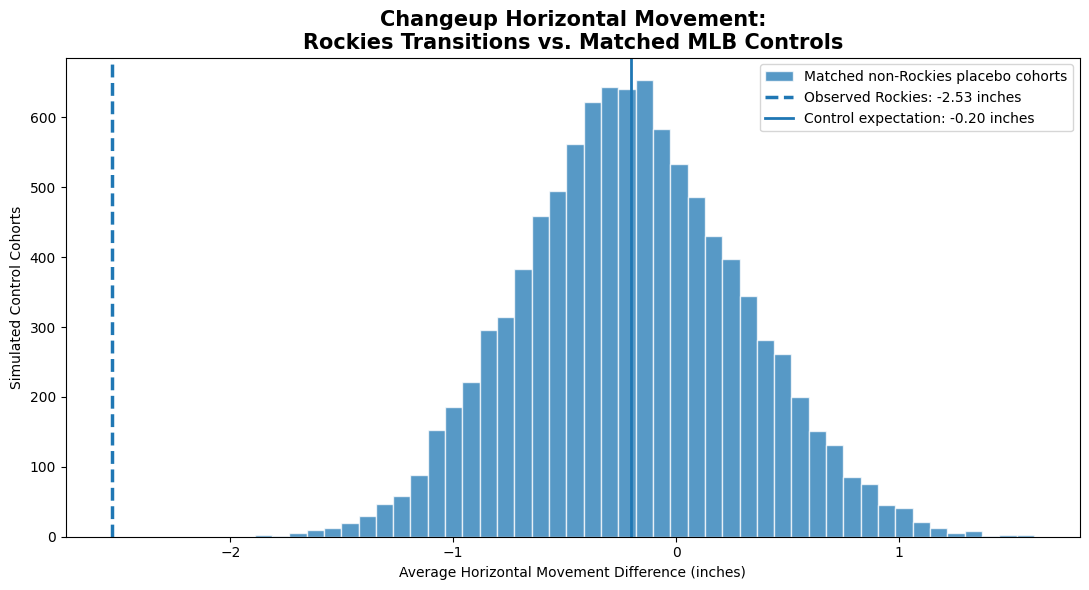


Control analysis saved successfully.


In [16]:
# ============================================================
# STEP 16: CHANGEUP MOVEMENT VS MLB CONTROL GROUP
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")

# ------------------------------------------------------------
# 1. Load our existing data
# ------------------------------------------------------------

master = pd.read_csv(
    DATA_PATH / "coors_master_pitch_types_long.csv"
)

rockies_roster = pd.read_csv(
    DATA_PATH / "rockies_pitchers_2015_2026.csv"
)

detail = pd.read_csv(
    DATA_PATH / "coors_changeup_cutter_detailed.csv"
)

# Our previously verified 100% Rockies changeup sample
rockies_sample = detail[
    detail["pitch_type"] == "changeup"
].copy()

rockies_sample["horizontal_difference"] = pd.to_numeric(
    rockies_sample["horizontal_difference"],
    errors="raise"
)

# Average repeated transitions at the pitcher level
observed_pitchers = (
    rockies_sample
    .groupby("player_id", as_index=False)
    .agg(
        player_name=("player_name", "first"),
        movement_change=("horizontal_difference", "mean")
    )
)

observed_mean = observed_pitchers["movement_change"].mean()
observed_negative = (
    observed_pitchers["movement_change"] < 0
).sum()

print("OBSERVED ROCKIES RESULTS")
print("Unique pitchers:", len(observed_pitchers))
print("Average movement change:", round(observed_mean, 2))
print(
    "Pitchers with reduced movement:",
    observed_negative, "of", len(observed_pitchers)
)

# ------------------------------------------------------------
# 2. Build a non-Rockies control population
# ------------------------------------------------------------

# Exclude anyone with a Rockies appearance during our period
ever_rockies = set(
    rockies_roster["player_id"].astype(int)
)

controls = master[
    (master["pitch_type"] == "changeup")
    & (~master["player_id"].isin(ever_rockies))
    & (master["player_id"] != 519381)
].copy()

numeric_cols = [
    "pa", "usage_percent", "avg_break_x"
]

for col in numeric_cols:
    controls[col] = pd.to_numeric(
        controls[col],
        errors="coerce"
    )

# Match our original quality thresholds
controls = controls[
    (controls["pa"] >= 100)
    & (controls["usage_percent"] >= 5)
].copy()

controls = controls.dropna(
    subset=["avg_break_x"]
)

# Convert horizontal movement to magnitude
controls["movement"] = controls["avg_break_x"].abs()

# Check uniqueness
assert not controls.duplicated(
    ["player_id", "year"]
).any(), "Duplicate control pitcher-seasons found."

print("\nCONTROL POPULATION")
print("Eligible pitchers:", controls["player_id"].nunique())
print("Eligible pitcher-seasons:", len(controls))

# ------------------------------------------------------------
# 3. Calculate ordinary year-to-year MLB fluctuations
# ------------------------------------------------------------

controls = controls.sort_values(
    ["player_id", "year"]
).copy()

controls["previous_year"] = (
    controls.groupby("player_id")["year"].shift(1)
)

controls["previous_movement"] = (
    controls.groupby("player_id")["movement"].shift(1)
)

controls["year_gap"] = (
    controls["year"] - controls["previous_year"]
)

# Consecutive seasons only
control_pairs = controls[
    controls["year_gap"] == 1
].copy()

# Exclude tracking-system transition
control_pairs = control_pairs[
    ~(
        (control_pairs["previous_year"] == 2019)
        & (control_pairs["year"] == 2020)
    )
].copy()

control_pairs["movement_change"] = (
    control_pairs["movement"]
    - control_pairs["previous_movement"]
)

control_pairs["absolute_change"] = (
    control_pairs["movement_change"].abs()
)

print("\nNORMAL MLB YEAR-TO-YEAR CHANGEUP VARIATION")
print("Consecutive-year comparisons:", len(control_pairs))

print(
    "Median absolute change:",
    round(control_pairs["absolute_change"].median(), 2)
)

print(
    "Mean absolute change:",
    round(control_pairs["absolute_change"].mean(), 2)
)

print(
    "90th percentile absolute change:",
    round(control_pairs["absolute_change"].quantile(0.90), 2)
)

# ------------------------------------------------------------
# 4. Construct calendar-year-matched placebo comparisons
# ------------------------------------------------------------

# Index each control pitcher's seasons and movement magnitudes
control_histories = {
    int(pid): dict(zip(group["year"], group["movement"]))
    for pid, group in controls.groupby("player_id")
}

matched_control_values = {}
matching_summary = []

for rockies_pid, events in rockies_sample.groupby("player_id"):

    rockies_pid = int(rockies_pid)
    placebo_values = []

    # Find control pitchers with all seasons required
    # for this Rockies pitcher's transition(s)
    for control_pid, history in control_histories.items():

        required_years = set(
            events["rockies_year"].astype(int)
        ) | set(
            events["other_year"].astype(int)
        )

        if not required_years.issubset(history):
            continue

        # Orient each placebo comparison exactly like
        # the Rockies-minus-other comparison.
        differences = []

        for event in events.itertuples():

            rockies_year = int(event.rockies_year)
            other_year = int(event.other_year)

            difference = (
                history[rockies_year]
                - history[other_year]
            )

            differences.append(difference)

        # Average when the Rockies pitcher has
        # multiple transitions, just as in Step 15
        placebo_values.append(np.mean(differences))

    if not placebo_values:
        raise ValueError(
            f"No matched controls for Rockies pitcher {rockies_pid}"
        )

    matched_control_values[rockies_pid] = np.array(
        placebo_values
    )

    matching_summary.append({
        "player_id": rockies_pid,
        "player_name": events["player_name"].iloc[0],
        "matched_control_candidates": len(placebo_values),
        "control_mean": np.mean(placebo_values)
    })

matching_df = pd.DataFrame(matching_summary)

print("\nMATCHED CONTROL AVAILABILITY")
display(matching_df)

# ------------------------------------------------------------
# 5. Simulate 10,000 matched control samples
# ------------------------------------------------------------

rng = np.random.default_rng(42)

N_SIMULATIONS = 10000

simulated_columns = []

for pid in observed_pitchers["player_id"]:

    values = matched_control_values[int(pid)]

    simulated_columns.append(
        rng.choice(
            values,
            size=N_SIMULATIONS,
            replace=True
        )
    )

# Each simulated row represents an 11-pitcher
# placebo cohort matched to the Rockies transitions
simulated = np.column_stack(simulated_columns)

simulated_means = simulated.mean(axis=1)

simulated_negative_counts = (
    simulated < 0
).sum(axis=1)

# Fraction of simulated averages as low as the
# observed Rockies average
empirical_p = (
    np.sum(simulated_means <= observed_mean) + 1
) / (N_SIMULATIONS + 1)

direction_p = (
    np.sum(simulated_negative_counts >= observed_negative) + 1
) / (N_SIMULATIONS + 1)

# ------------------------------------------------------------
# 6. Report results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ROCKIES CHANGEUPS VS MATCHED MLB CONTROLS")
print("=" * 60)

print(
    "Rockies average movement difference:",
    round(observed_mean, 2)
)

print(
    "Matched control expected average:",
    round(simulated_means.mean(), 2)
)

print(
    "Control simulation 95% range:",
    np.percentile(simulated_means, [2.5, 97.5]).round(2)
)

print(
    "Rockies minus control expectation:",
    round(observed_mean - simulated_means.mean(), 2)
)

print(
    "Exploratory empirical lower-tail probability:",
    round(empirical_p, 5)
)

print(
    "Exploratory probability of matching directional consistency:",
    round(direction_p, 5)
)

# ------------------------------------------------------------
# 7. Visualize the comparison
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.hist(
    simulated_means,
    bins=45,
    alpha=0.75,
    edgecolor="white",
    label="Matched non-Rockies placebo cohorts"
)

plt.axvline(
    observed_mean,
    linewidth=2.5,
    linestyle="--",
    label=f"Observed Rockies: {observed_mean:.2f} inches"
)

plt.axvline(
    simulated_means.mean(),
    linewidth=2,
    label=f"Control expectation: {simulated_means.mean():.2f} inches"
)

plt.title(
    "Changeup Horizontal Movement:\n"
    "Rockies Transitions vs. Matched MLB Controls",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Average Horizontal Movement Difference (inches)")
plt.ylabel("Simulated Control Cohorts")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Save outputs
# ------------------------------------------------------------

control_pairs.to_csv(
    DATA_PATH / "mlb_changeup_yearly_variation.csv",
    index=False
)

matching_df.to_csv(
    DATA_PATH / "coors_changeup_matched_controls.csv",
    index=False
)

simulation_summary = pd.DataFrame({
    "simulated_mean": simulated_means,
    "negative_count": simulated_negative_counts
})

simulation_summary.to_csv(
    DATA_PATH / "coors_changeup_control_simulations.csv",
    index=False
)

print("\nControl analysis saved successfully.")

Step 17 — Test whether the data is available

In [17]:
%pip -q install pybaseball

from pybaseball import statcast_pitcher
import pandas as pd
import numpy as np

# Jon Gray — 2021 Rockies season
pitches = statcast_pitcher(
    start_dt="2021-04-01",
    end_dt="2021-10-03",
    player_id=592351
)

# Regular-season changeups
ch = pitches[
    (pitches["pitch_type"] == "CH")
    & (pitches["game_type"] == "R")
].copy()

ch["pfx_x"] = pd.to_numeric(ch["pfx_x"], errors="coerce")
ch = ch.dropna(subset=["pfx_x"])

# Identify Rockies home vs road games
ch["environment"] = np.select(
    [
        ch["home_team"] == "COL",
        ch["away_team"] == "COL"
    ],
    [
        "Rockies Home",
        "Rockies Road"
    ],
    default="Other"
)

ch = ch[ch["environment"] != "Other"]

# pfx_x is measured in feet; convert to inches
ch["horizontal_inches"] = ch["pfx_x"] * 12

summary = (
    ch.groupby("environment")
    .agg(
        pitches=("horizontal_inches", "size"),
        avg_signed_movement=("horizontal_inches", "mean")
    )
    .reset_index()
)

summary["movement_magnitude"] = (
    summary["avg_signed_movement"].abs()
)

print("JON GRAY — 2021 CHANGEUP MOVEMENT")
display(summary.round(2))

if set(summary["environment"]) == {
    "Rockies Home", "Rockies Road"
}:
    home = summary.set_index("environment").loc[
        "Rockies Home", "movement_magnitude"
    ]
    road = summary.set_index("environment").loc[
        "Rockies Road", "movement_magnitude"
    ]

    print(
        "\nHome minus road movement magnitude:",
        round(home - road, 2),
        "inches"
    )

Gathering Player Data
JON GRAY — 2021 CHANGEUP MOVEMENT


,environment,pitches,avg_signed_movement,movement_magnitude
0,Rockies Home,113,-10.1,10.1
1,Rockies Road,91,-13.6,13.6



Home minus road movement magnitude: -3.5 inches


Step 18 — Make sure Jon Gray's result isn't driven by a few games

In [18]:
# ============================================================
# STEP 18: JON GRAY HOME/ROAD GAME-LEVEL ROBUSTNESS
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")

df = ch.copy()

for col in ["horizontal_inches", "release_speed",
            "release_spin_rate"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Home/road pitch characteristics
summary = (
    df.groupby("environment")
    .agg(
        games=("game_pk", "nunique"),
        pitches=("horizontal_inches", "size"),
        signed_movement=("horizontal_inches", "mean"),
        velocity=("release_speed", "mean"),
        spin_rpm=("release_spin_rate", "mean")
    )
    .reset_index()
)

summary["movement_magnitude"] = (
    summary["signed_movement"].abs()
)

print("JON GRAY — HOME VS ROAD PITCH CHARACTERISTICS")
display(summary.round(2))

# Aggregate pitch movement within each game
games = (
    df.groupby(["environment", "game_pk"])
    .agg(
        pitch_count=("horizontal_inches", "size"),
        movement_sum=("horizontal_inches", "sum")
    )
    .reset_index()
)

home = games[games["environment"] == "Rockies Home"]
road = games[games["environment"] == "Rockies Road"]

if home.empty or road.empty:
    raise ValueError("Both home and road games are required.")

# Cluster bootstrap: sample entire games with replacement
rng = np.random.default_rng(42)
B = 10000

def bootstrap_game_means(group):
    n = len(group)
    indices = rng.integers(0, n, size=(B, n))

    sums = group["movement_sum"].to_numpy()
    counts = group["pitch_count"].to_numpy()

    return (
        sums[indices].sum(axis=1)
        / counts[indices].sum(axis=1)
    )

home_boot = bootstrap_game_means(home)
road_boot = bootstrap_game_means(road)

# Same magnitude definition used in our original comparison
boot_difference = (
    np.abs(home_boot) - np.abs(road_boot)
)

lower, upper = np.percentile(
    boot_difference, [2.5, 97.5]
)

actual = (
    abs(df.loc[df["environment"] == "Rockies Home",
               "horizontal_inches"].mean())
    -
    abs(df.loc[df["environment"] == "Rockies Road",
               "horizontal_inches"].mean())
)

print("\nGAME-LEVEL BOOTSTRAP RESULTS")
print("Home games:", len(home))
print("Road games:", len(road))
print("Observed home minus road:", round(actual, 2), "inches")
print(
    "95% bootstrap interval:",
    round(lower, 2), "to", round(upper, 2), "inches"
)

print(
    "Bootstrap percentage with less movement at home:",
    round(100 * (boot_difference < 0).mean(), 2), "%"
)

# Save result
summary.to_csv(
    DATA_PATH / "jon_gray_2021_home_road_changeup.csv",
    index=False
)

JON GRAY — HOME VS ROAD PITCH CHARACTERISTICS


,environment,games,pitches,signed_movement,velocity,spin_rpm,movement_magnitude
0,Rockies Home,14,113,-10.1,87.49,1441.39,10.1
1,Rockies Road,14,91,-13.6,87.73,1476.45,13.6



GAME-LEVEL BOOTSTRAP RESULTS
Home games: 14
Road games: 14
Observed home minus road: -3.5 inches
95% bootstrap interval: -4.8 to -2.12 inches
Bootstrap percentage with less movement at home: 100.0 %


Step 19 — Replicate this across our 11 changeup pitchers

In [19]:
# ============================================================
# STEP 19: HOME VS ROAD CHANGEUP MOVEMENT — 11 PITCHERS
# ============================================================

import pandas as pd
import numpy as np
import time
from pathlib import Path
from pybaseball import statcast_pitcher

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")
CACHE_DIR = DATA_PATH / "Statcast_Changeups"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Our previously verified 100% Rockies transitions
detail = pd.read_csv(
    DATA_PATH / "coors_changeup_cutter_detailed.csv"
)

# Unique pitcher-season combinations
pitchers = (
    detail[detail["pitch_type"] == "changeup"]
    [["player_id", "player_name", "rockies_year"]]
    .drop_duplicates()
    .sort_values(["rockies_year", "player_name"])
)

print("Unique pitcher-seasons to check:", len(pitchers))

results = []
failures = []

for row in pitchers.itertuples(index=False):

    pid = int(row.player_id)
    year = int(row.rockies_year)
    name = row.player_name

    print(f"\nChecking {name} — {year}")

    cache_file = CACHE_DIR / f"{pid}_{year}_CH.csv"

    try:
        if cache_file.exists():
            ch = pd.read_csv(cache_file)

        else:
            raw = statcast_pitcher(
                start_dt=f"{year}-03-01",
                end_dt=f"{year}-11-15",
                player_id=pid
            )

            if raw is None or raw.empty:
                raise ValueError("No Statcast pitches returned")

            # Regular-season changeups only
            ch = raw[
                (raw["pitch_type"] == "CH")
                & (raw["game_type"] == "R")
            ][[
                "game_pk",
                "game_date",
                "home_team",
                "away_team",
                "pfx_x",
                "release_speed",
                "release_spin_rate"
            ]].copy()

            ch.to_csv(cache_file, index=False)
            time.sleep(1)

        if ch.empty:
            raise ValueError("No changeups found")

        # Convert Statcast movement from feet to inches
        ch["horizontal_inches"] = (
            pd.to_numeric(ch["pfx_x"], errors="coerce") * 12
        )

        ch = ch.dropna(subset=["horizontal_inches"])

        # Identify Colorado home and road appearances
        ch["environment"] = np.select(
            [
                ch["home_team"] == "COL",
                ch["away_team"] == "COL"
            ],
            [
                "Home",
                "Road"
            ],
            default="Other"
        )

        ch = ch[ch["environment"].isin(["Home", "Road"])]

        summary = (
            ch.groupby("environment")
            .agg(
                pitches=("horizontal_inches", "size"),
                games=("game_pk", "nunique"),
                signed_movement=("horizontal_inches", "mean")
            )
        )

        if not {"Home", "Road"}.issubset(summary.index):
            raise ValueError("Missing home or road observations")

        home = summary.loc["Home"]
        road = summary.loc["Road"]

        home_movement = abs(home["signed_movement"])
        road_movement = abs(road["signed_movement"])

        difference = home_movement - road_movement

        # Flag low-exposure comparisons without discarding them
        sufficient_sample = (
            home["pitches"] >= 20
            and road["pitches"] >= 20
            and home["games"] >= 3
            and road["games"] >= 3
        )

        results.append({
            "player_id": pid,
            "player_name": name,
            "year": year,
            "home_games": int(home["games"]),
            "road_games": int(road["games"]),
            "home_pitches": int(home["pitches"]),
            "road_pitches": int(road["pitches"]),
            "home_movement": home_movement,
            "road_movement": road_movement,
            "home_minus_road": difference,
            "sufficient_sample": sufficient_sample
        })

    except Exception as e:
        failures.append({
            "player_name": name,
            "year": year,
            "error": str(e)
        })
        print("Unable to calculate:", e)

# ============================================================
# RESULTS
# ============================================================

results_df = pd.DataFrame(results)

print("\n" + "=" * 65)
print("ROCKIES CHANGEUP HOME VS ROAD ANALYSIS")
print("=" * 65)

print("Pitcher-seasons requested:", len(pitchers))
print("Successful comparisons:", len(results))
print("Failed comparisons:", len(failures))

if not results_df.empty:

    display(
        results_df.sort_values("home_minus_road").round(2)
    )

    valid = results_df[
        results_df["sufficient_sample"]
    ].copy()

    print("\nCOMPARISONS WITH ADEQUATE PITCH/GAME COUNTS")
    print("Qualifying pitchers:", len(valid))

    if not valid.empty:
        print(
            "Average home-road difference:",
            round(valid["home_minus_road"].mean(), 2),
            "inches"
        )

        print(
            "Median home-road difference:",
            round(valid["home_minus_road"].median(), 2),
            "inches"
        )

        print(
            "Pitchers with less movement at home:",
            int((valid["home_minus_road"] < 0).sum()),
            "of",
            len(valid)
        )

    results_df.to_csv(
        DATA_PATH / "coors_changeups_home_road_11_pitchers.csv",
        index=False
    )

if failures:
    print("\nFAILED COMPARISONS")
    display(pd.DataFrame(failures))

Unique pitcher-seasons to check: 11

Checking Kahnle, Tommy — 2015

Checking Bergman, Christian — 2016

Checking Butler, Eddie — 2016

Checking Almonte, Yency — 2021

Checking Gomber, Austin — 2021

Checking Gray, Jon — 2021

Checking Estévez, Carlos — 2022

Checking Suter, Brent — 2023

Checking Molina, Anthony — 2025

Checking Bernardino, Brennan — 2026

Checking Quintana, Jose — 2026

ROCKIES CHANGEUP HOME VS ROAD ANALYSIS
Pitcher-seasons requested: 11
Successful comparisons: 11
Failed comparisons: 0


,player_id,player_name,year,home_games,road_games,home_pitches,road_pitches,home_movement,road_movement,home_minus_road,sufficient_sample
2,572750,"Butler, Eddie",2016,7,7,47,28,7.35,12.80,-5.45,True
1,548357,"Bergman, Christian",2016,6,8,38,38,9.92,14.01,-4.09,True
3,622075,"Almonte, Yency",2021,19,15,53,36,12.34,16.04,-3.70,True
8,683627,"Molina, Anthony",2025,11,6,72,38,12.37,16.03,-3.66,True
5,592351,"Gray, Jon",2021,14,14,113,91,10.10,13.60,-3.50,True
10,500779,"Quintana, Jose",2026,5,6,85,80,11.79,14.83,-3.04,True
9,657514,"Bernardino, Brennan",2026,24,18,47,27,11.39,13.82,-2.43,True
4,596295,"Gomber, Austin",2021,9,14,155,205,8.56,10.98,-2.42,True
7,608718,"Suter, Brent",2023,26,29,163,156,7.64,9.45,-1.81,True
0,592454,"Kahnle, Tommy",2015,18,17,106,158,11.04,12.49,-1.44,True



COMPARISONS WITH ADEQUATE PITCH/GAME COUNTS
Qualifying pitchers: 11
Average home-road difference: -2.98 inches
Median home-road difference: -3.04 inches
Pitchers with less movement at home: 11 of 11


Step 20 — Test a new group of Rockies pitchers

In [20]:
# ============================================================
# STEP 20: INDEPENDENT 2024 ROCKIES CHANGEUP VALIDATION
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from pybaseball import statcast_pitcher

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")
CACHE = DATA_PATH / "Statcast_2024_Validation"
CACHE.mkdir(parents=True, exist_ok=True)

master = pd.read_csv(
    DATA_PATH / "coors_master_pitch_types_long.csv"
)

for col in ["year", "pa", "usage_percent"]:
    master[col] = pd.to_numeric(master[col], errors="coerce")

# Choose eligible pitchers BEFORE examining home-road movement
eligible = (
    master[
        (master["year"] == 2024)
        & (master["rockies"].astype(str).str.upper() == "Y")
        & (master["pitch_type"] == "changeup")
        & (master["pa"] >= 100)
        & (master["usage_percent"] >= 5)
    ][["player_id", "player_name"]]
    .drop_duplicates("player_id")
    .sort_values("player_name")
)

print("2024 eligible Rockies changeup pitchers:", len(eligible))

results = []
failures = []

for row in eligible.itertuples(index=False):

    pid = int(row.player_id)
    name = row.player_name

    print(f"Checking {name}")

    cache_file = CACHE / f"{pid}_2024_COL_CH.csv"

    try:
        if cache_file.exists():
            ch = pd.read_csv(cache_file)
        else:
            raw = statcast_pitcher(
                start_dt="2024-03-01",
                end_dt="2024-10-05",
                player_id=pid
            )

            if raw is None or raw.empty:
                raise ValueError("No Statcast records")

            raw = raw[
                (raw["game_type"] == "R")
                & (raw["pitch_type"] == "CH")
            ].copy()

            # Identify the pitcher's actual team:
            # Top inning = home team pitching
            # Bottom inning = away team pitching
            half = raw["inning_topbot"].astype(str).str.lower()

            top = half.str.startswith("top")
            bottom = half.str.startswith("bot")

            raw = raw.loc[top | bottom].copy()

            top = raw["inning_topbot"].str.lower().str.startswith("top")

            raw["pitching_team"] = np.where(
                top,
                raw["home_team"],
                raw["away_team"]
            )

            # Keep only pitches actually thrown for Colorado
            ch = raw[
                raw["pitching_team"] == "COL"
            ].copy()

            ch["environment"] = np.where(
                ch["home_team"] == "COL",
                "Home",
                "Road"
            )

            ch = ch[
                ["game_pk", "environment", "pfx_x",
                 "release_speed", "release_spin_rate"]
            ].copy()

            ch.to_csv(cache_file, index=False)

        ch["movement_inches"] = (
            pd.to_numeric(ch["pfx_x"], errors="coerce") * 12
        )

        ch = ch.dropna(subset=["movement_inches"])

        summary = (
            ch.groupby("environment")
            .agg(
                pitches=("movement_inches", "size"),
                games=("game_pk", "nunique"),
                signed_movement=("movement_inches", "mean")
            )
        )

        if not {"Home", "Road"}.issubset(summary.index):
            raise ValueError("Missing home or road sample")

        home = summary.loc["Home"]
        road = summary.loc["Road"]

        sufficient = (
            home["pitches"] >= 20
            and road["pitches"] >= 20
            and home["games"] >= 3
            and road["games"] >= 3
        )

        home_mag = abs(home["signed_movement"])
        road_mag = abs(road["signed_movement"])

        results.append({
            "player_name": name,
            "player_id": pid,
            "home_games": int(home["games"]),
            "road_games": int(road["games"]),
            "home_pitches": int(home["pitches"]),
            "road_pitches": int(road["pitches"]),
            "home_movement": home_mag,
            "road_movement": road_mag,
            "difference": home_mag - road_mag,
            "pct_change": (
                100 * (home_mag - road_mag) / road_mag
                if road_mag > 0 else np.nan
            ),
            "direction_reversed": (
                home["signed_movement"]
                * road["signed_movement"] < 0
            ),
            "sufficient_sample": sufficient
        })

    except Exception as exc:
        failures.append({
            "player_name": name,
            "error": str(exc)
        })

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\n" + "=" * 60)
print("2024 ROCKIES CHANGEUP VALIDATION")
print("=" * 60)

print("Eligible pitchers:", len(eligible))
print("Successfully retrieved:", len(results))
print("Retrieval failures:", len(failures))

if not results_df.empty:

    display(
        results_df.sort_values("difference").round(2)
    )

    valid = results_df[
        results_df["sufficient_sample"]
    ].copy()

    print("\nQUALIFYING HOME-ROAD COMPARISONS")
    print("Pitchers:", len(valid))

    if not valid.empty:

        print(
            "Average home-road difference:",
            round(valid["difference"].mean(), 2),
            "inches"
        )

        print(
            "Median home-road difference:",
            round(valid["difference"].median(), 2),
            "inches"
        )

        print(
            "Less movement at home:",
            int((valid["difference"] < 0).sum()),
            "of", len(valid)
        )

        print(
            "Average percentage change:",
            round(valid["pct_change"].mean(), 2), "%"
        )

        print(
            "Movement-direction reversals:",
            int(valid["direction_reversed"].sum())
        )

    results_df.to_csv(
        DATA_PATH / "coors_2024_changeup_validation.csv",
        index=False
    )

if failures:
    print("\nRETRIEVAL FAILURES")
    display(pd.DataFrame(failures))

2024 eligible Rockies changeup pitchers: 11
Checking Beeks, Jalen
Checking Blach, Ty
Checking Chivilli, Angel
Checking Feltner, Ryan
Checking Freeland, Kyle
Checking Gomber, Austin
Checking Gordon, Tanner
Checking Hudson, Dakota
Checking Lambert, Peter
Checking Molina, Anthony
Checking Vodnik, Victor

2024 ROCKIES CHANGEUP VALIDATION
Eligible pitchers: 11
Successfully retrieved: 11
Retrieval failures: 0


,player_name,player_id,home_games,road_games,home_pitches,road_pitches,home_movement,road_movement,difference,pct_change,direction_reversed,sufficient_sample
1,"Blach, Ty",621389,13,7,206,72,12.69,17.60,-4.92,-27.94,False,True
7,"Hudson, Dakota",641712,10,8,94,58,10.83,15.28,-4.45,-29.13,False,True
8,"Lambert, Peter",663567,11,16,104,156,9.47,13.34,-3.87,-29.04,False,True
0,"Beeks, Jalen",656222,22,21,75,138,12.31,16.14,-3.83,-23.74,False,True
10,"Vodnik, Victor",680767,30,29,111,111,11.35,14.84,-3.48,-23.48,False,True
4,"Freeland, Kyle",607536,10,11,83,123,10.25,13.33,-3.08,-23.12,False,True
5,"Gomber, Austin",596295,14,16,240,298,8.39,11.44,-3.04,-26.60,False,True
2,"Chivilli, Angel",683409,17,12,133,73,9.66,12.70,-3.03,-23.89,False,True
9,"Molina, Anthony",683627,16,16,115,120,11.83,14.79,-2.96,-20.04,False,True
6,"Gordon, Tanner",685299,2,6,37,79,12.40,14.73,-2.32,-15.78,False,False



QUALIFYING HOME-ROAD COMPARISONS
Pitchers: 10
Average home-road difference: -3.36 inches
Median home-road difference: -3.28 inches
Less movement at home: 10 of 10
Average percentage change: -24.23 %
Movement-direction reversals: 0


Step 21 — Test your gyro-spin hypothesis

In [21]:
# ============================================================
# STEP 21: 2024 ROCKIES — MOVEMENT BY PITCH TYPE
# Test overall horizontal + induced-vertical movement
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from pybaseball import statcast_pitcher

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")
CACHE = DATA_PATH / "Statcast_2024_AllPitches"
CACHE.mkdir(parents=True, exist_ok=True)

master = pd.read_csv(
    DATA_PATH / "coors_master_pitch_types_long.csv"
)

pitch_codes = {
    "four_seam": "FF",
    "sinker": "SI",
    "changeup": "CH",
    "slider": "SL",
    "cutter": "FC",
    "curveball": "CU",
    "sweeper": "ST"
}

for col in ["year", "pa", "usage_percent"]:
    master[col] = pd.to_numeric(master[col], errors="coerce")

# Select pitchers and pitch types by usage,
# without inspecting home-road movement first
eligible = master[
    (master["year"] == 2024)
    & (master["rockies"].astype(str).str.upper() == "Y")
    & (master["pitch_type"].isin(pitch_codes))
    & (master["pa"] >= 100)
    & (master["usage_percent"] >= 5)
][["player_id", "player_name", "pitch_type"]].drop_duplicates()

eligible["statcast_code"] = (
    eligible["pitch_type"].map(pitch_codes)
)

results = []
failures = []

print("Eligible pitchers:", eligible["player_id"].nunique())
print("Eligible pitcher-pitch combinations:", len(eligible))

for pid, targets in eligible.groupby("player_id"):

    pid = int(pid)
    name = targets["player_name"].iloc[0]

    print(f"Checking {name}")

    cache_file = CACHE / f"{pid}_2024_COL_all.csv"

    try:
        if cache_file.exists():
            pitches = pd.read_csv(cache_file)
        else:
            raw = statcast_pitcher(
                start_dt="2024-03-01",
                end_dt="2024-10-05",
                player_id=pid
            )

            if raw is None or raw.empty:
                raise ValueError("No pitch records")

            half = (
                raw["inning_topbot"]
                .astype(str)
                .str.lower()
            )

            # Home team pitches in top half;
            # away team pitches in bottom half
            pitching_for_col = (
                ((raw["home_team"] == "COL")
                 & half.str.startswith("top"))
                |
                ((raw["away_team"] == "COL")
                 & half.str.startswith("bot"))
            )

            pitches = raw.loc[
                pitching_for_col
                & (raw["game_type"] == "R"),
                [
                    "game_pk",
                    "pitch_type",
                    "home_team",
                    "pfx_x",
                    "pfx_z"
                ]
            ].copy()

            pitches["environment"] = np.where(
                pitches["home_team"] == "COL",
                "Home",
                "Road"
            )

            pitches.to_csv(cache_file, index=False)

        for col in ["pfx_x", "pfx_z"]:
            pitches[col] = pd.to_numeric(
                pitches[col], errors="coerce"
            )

        for target in targets.itertuples(index=False):

            subset = pitches[
                pitches["pitch_type"] == target.statcast_code
            ].dropna(subset=["pfx_x", "pfx_z"]).copy()

            if subset.empty:
                continue

            summary = (
                subset.groupby("environment")
                .agg(
                    pitches=("game_pk", "size"),
                    games=("game_pk", "nunique"),
                    horizontal=("pfx_x", "mean"),
                    vertical=("pfx_z", "mean")
                )
            )

            if not {"Home", "Road"}.issubset(summary.index):
                continue

            home = summary.loc["Home"]
            road = summary.loc["Road"]

            # Statcast pfx measurements are in feet
            home_h = home["horizontal"] * 12
            road_h = road["horizontal"] * 12
            home_v = home["vertical"] * 12
            road_v = road["vertical"] * 12

            home_total = np.hypot(home_h, home_v)
            road_total = np.hypot(road_h, road_v)

            sufficient = (
                home["pitches"] >= 20
                and road["pitches"] >= 20
                and home["games"] >= 3
                and road["games"] >= 3
            )

            results.append({
                "player_id": pid,
                "player_name": name,
                "pitch_type": target.pitch_type,
                "home_pitches": int(home["pitches"]),
                "road_pitches": int(road["pitches"]),
                "home_games": int(home["games"]),
                "road_games": int(road["games"]),
                "home_total_movement": home_total,
                "road_total_movement": road_total,
                "movement_difference": (
                    home_total - road_total
                ),
                "pct_difference": (
                    100 * (home_total - road_total) / road_total
                    if road_total > 0 else np.nan
                ),
                "horizontal_difference": (
                    abs(home_h) - abs(road_h)
                ),
                "vertical_difference": home_v - road_v,
                "sufficient_sample": sufficient
            })

    except Exception as exc:
        failures.append({
            "player_name": name,
            "error": str(exc)
        })

# ------------------------------------------------------------
# Summarize qualifying pitcher-pitch comparisons
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\n" + "=" * 65)
print("2024 ROCKIES — HOME VS ROAD BY PITCH TYPE")
print("=" * 65)

print("Successful pitcher-pitch comparisons:", len(results_df))
print("Retrieval failures:", len(failures))

if not results_df.empty:

    valid = results_df[
        results_df["sufficient_sample"]
    ].copy()

    summary = (
        valid.groupby("pitch_type")
        .agg(
            pitchers=("player_id", "nunique"),
            avg_road_movement=(
                "road_total_movement", "mean"
            ),
            avg_home_movement=(
                "home_total_movement", "mean"
            ),
            mean_difference=(
                "movement_difference", "mean"
            ),
            median_difference=(
                "movement_difference", "median"
            ),
            mean_pct_difference=(
                "pct_difference", "mean"
            ),
            pct_less_movement=(
                "movement_difference",
                lambda x: 100 * (x < 0).mean()
            )
        )
        .reset_index()
        .sort_values("mean_difference")
    )

    print("\nOVERALL MOVEMENT MAGNITUDE")
    display(summary.round(2))

    print("\nINDIVIDUAL PITCHER-PITCH RESULTS")
    display(
        valid.sort_values(
            ["pitch_type", "movement_difference"]
        ).round(2)
    )

    # Check against our previous changeup analysis
    ch = valid[valid["pitch_type"] == "changeup"]

    if not ch.empty:
        print(
            "\nChangeup horizontal difference (validation):",
            round(ch["horizontal_difference"].mean(), 2),
            "inches"
        )

    summary.to_csv(
        DATA_PATH / "coors_2024_pitch_type_movement_summary.csv",
        index=False
    )

    results_df.to_csv(
        DATA_PATH / "coors_2024_pitch_type_movement_detail.csv",
        index=False
    )

if failures:
    print("\nFAILED RETRIEVALS")
    display(pd.DataFrame(failures))

Eligible pitchers: 17
Eligible pitcher-pitch combinations: 61
Checking Gomber, Austin
Checking Freeland, Kyle
Checking Quantrill, Cal
Checking Blach, Ty
Checking Hudson, Dakota
Checking Kinley, Tyler
Checking Beeks, Jalen
Checking Bird, Jake
Checking Feltner, Ryan
Checking Lambert, Peter
Checking Lawrence, Justin
Checking Vodnik, Victor
Checking Mears, Nick
Checking Chivilli, Angel
Checking Molina, Anthony
Checking Gordon, Tanner
Checking Blalock, Bradley

2024 ROCKIES — HOME VS ROAD BY PITCH TYPE
Successful pitcher-pitch comparisons: 59
Retrieval failures: 0

OVERALL MOVEMENT MAGNITUDE


,pitch_type,pitchers,avg_road_movement,avg_home_movement,mean_difference,median_difference,mean_pct_difference,pct_less_movement
4,sinker,7,17.08,13.14,-3.93,-3.94,-23.17,100.0
0,changeup,10,15.28,11.59,-3.69,-3.83,-23.49,100.0
3,four_seam,12,17.91,14.37,-3.55,-3.55,-20.05,100.0
1,curveball,7,11.44,9.07,-2.37,-2.11,-21.64,100.0
6,sweeper,2,14.20,12.47,-1.74,-1.74,-12.38,100.0
5,slider,10,6.02,4.70,-1.32,-1.12,-20.01,100.0
2,cutter,5,6.22,5.08,-1.14,-1.29,-11.14,80.0



INDIVIDUAL PITCHER-PITCH RESULTS


,player_id,player_name,pitch_type,home_pitches,road_pitches,home_games,road_games,home_total_movement,road_total_movement,movement_difference,pct_difference,horizontal_difference,vertical_difference,sufficient_sample
14,621389,"Blach, Ty",changeup,206,72,13,7,12.79,17.61,-4.83,-27.40,-4.92,-1.13,True
48,683409,"Chivilli, Angel",changeup,133,73,17,12,10.81,15.27,-4.47,-29.24,-3.03,-3.65,True
19,641712,"Hudson, Dakota",changeup,94,58,10,8,11.21,15.51,-4.30,-27.73,-4.45,0.25,True
37,663567,"Lambert, Peter",changeup,104,156,11,16,10.90,15.00,-4.09,-27.29,-3.87,-1.44,True
2,596295,"Gomber, Austin",changeup,240,298,14,16,12.36,16.24,-3.88,-23.90,-3.04,-2.46,True
52,683627,"Molina, Anthony",changeup,115,120,16,16,13.54,17.32,-3.78,-21.82,-2.96,-2.42,True
24,656222,"Beeks, Jalen",changeup,75,138,22,21,14.68,18.37,-3.69,-20.07,-3.83,-0.77,True
6,607536,"Freeland, Kyle",changeup,83,123,10,11,11.23,14.84,-3.61,-24.30,-3.08,-1.92,True
42,680767,"Vodnik, Victor",changeup,111,111,30,29,11.37,14.84,-3.47,-23.40,-3.48,0.49,True
34,663372,"Feltner, Ryan",changeup,190,189,15,15,7.05,7.81,-0.76,-9.79,-0.91,-0.13,True



Changeup horizontal difference (validation): -3.36 inches


**** Audit ****

In [22]:
# ============================================================
# METHODOLOGICAL AUDIT 1
# DATASET INTEGRITY AND SAMPLE ACCOUNTING
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")

master = pd.read_csv(
    DATA_PATH / "coors_master_pitch_types_long.csv"
)

results = pd.read_csv(
    DATA_PATH / "coors_2024_pitch_type_movement_detail.csv"
)

# ------------------------------------------------------------
# 1. Reconstruct eligibility
# ------------------------------------------------------------

for col in ["year", "pa", "usage_percent"]:
    master[col] = pd.to_numeric(master[col], errors="coerce")

pitch_types = [
    "four_seam", "sinker", "changeup",
    "slider", "cutter", "curveball", "sweeper"
]

eligible = master[
    (master["year"] == 2024)
    & (master["rockies"].astype(str).str.upper() == "Y")
    & (master["pitch_type"].isin(pitch_types))
    & (master["pa"] >= 100)
    & (master["usage_percent"] >= 5)
][
    ["player_id", "player_name", "pitch_type"]
].drop_duplicates()

print("=" * 60)
print("AUDIT 1 — DATASET INTEGRITY")
print("=" * 60)

print("Eligible pitchers:", eligible["player_id"].nunique())
print("Eligible pitcher-pitch combinations:", len(eligible))
print("Calculated comparisons:", len(results))

# ------------------------------------------------------------
# 2. Check duplicate comparisons
# ------------------------------------------------------------

duplicates = results[
    results.duplicated(
        ["player_id", "pitch_type"],
        keep=False
    )
]

print("\nDUPLICATE COMPARISONS:", len(duplicates))

if not duplicates.empty:
    display(duplicates)

# ------------------------------------------------------------
# 3. Identify eligible comparisons missing from results
# ------------------------------------------------------------

missing = eligible.merge(
    results[["player_id", "pitch_type"]],
    on=["player_id", "pitch_type"],
    how="left",
    indicator=True
)

missing = missing[
    missing["_merge"] == "left_only"
].drop(columns="_merge")

print("\nELIGIBLE COMBINATIONS WITHOUT COMPARISONS:")
display(missing)

# ------------------------------------------------------------
# 4. Recalculate qualification flags
# ------------------------------------------------------------

results["audit_qualifies"] = (
    (results["home_pitches"] >= 20)
    & (results["road_pitches"] >= 20)
    & (results["home_games"] >= 3)
    & (results["road_games"] >= 3)
)

original_flags = (
    results["sufficient_sample"]
    .astype(str)
    .str.lower()
    .eq("true")
)

print(
    "\nQualification flag mismatches:",
    int((original_flags != results["audit_qualifies"]).sum())
)

print("\nCOMPARISONS NOT MEETING SAMPLE REQUIREMENTS")

display(
    results.loc[
        ~results["audit_qualifies"],
        [
            "player_name",
            "pitch_type",
            "home_pitches",
            "road_pitches",
            "home_games",
            "road_games"
        ]
    ]
)

# ------------------------------------------------------------
# 5. Verify movement calculations
# ------------------------------------------------------------

expected_difference = (
    results["home_total_movement"]
    - results["road_total_movement"]
)

expected_pct = (
    100 * expected_difference
    / results["road_total_movement"]
)

difference_error = (
    results["movement_difference"]
    - expected_difference
).abs()

percentage_error = (
    results["pct_difference"]
    - expected_pct
).abs()

print("\nCALCULATION ACCURACY")

print(
    "Largest movement difference discrepancy:",
    round(difference_error.max(), 8)
)

print(
    "Largest percentage discrepancy:",
    round(percentage_error.max(), 8)
)

# ------------------------------------------------------------
# 6. Final sample accounting
# ------------------------------------------------------------

valid = results[results["audit_qualifies"]].copy()

print("\nFINAL SAMPLE ACCOUNTING")
print("-" * 60)

print("Eligible combinations:", len(eligible))
print("Calculated comparisons:", len(results))
print("Qualified comparisons:", len(valid))

print(
    "Qualified comparisons showing lower home movement:",
    int((valid["movement_difference"] < 0).sum())
)

print("\nQUALIFYING OBSERVATIONS BY PITCH TYPE")

summary = (
    valid.groupby("pitch_type")
    .agg(
        pitchers=("player_id", "nunique"),
        observations=("player_id", "size"),
        lower_home_movement=(
            "movement_difference",
            lambda x: int((x < 0).sum())
        ),
        mean_difference=("movement_difference", "mean"),
        mean_pct_difference=("pct_difference", "mean")
    )
    .reset_index()
)

display(summary.round(2))

# ------------------------------------------------------------
# 7. Automated integrity checks
# ------------------------------------------------------------

assert duplicates.empty, "Duplicate comparisons detected."

assert (
    original_flags == results["audit_qualifies"]
).all(), "Qualification flag mismatch."

assert difference_error.max() < 0.01, (
    "Movement difference calculation discrepancy."
)

assert percentage_error.max() < 0.05, (
    "Percentage calculation discrepancy."
)

print("\nBASIC INTEGRITY CHECKS PASSED")

AUDIT 1 — DATASET INTEGRITY
Eligible pitchers: 17
Eligible pitcher-pitch combinations: 61
Calculated comparisons: 59

DUPLICATE COMPARISONS: 0

ELIGIBLE COMBINATIONS WITHOUT COMPARISONS:


,player_id,player_name,pitch_type
40,607536,"Freeland, Kyle",curveball
44,596295,"Gomber, Austin",curveball



Qualification flag mismatches: 0

COMPARISONS NOT MEETING SAMPLE REQUIREMENTS


,player_name,pitch_type,home_pitches,road_pitches,home_games,road_games
53,"Gordon, Tanner",four_seam,77,225,2,6
54,"Gordon, Tanner",slider,44,118,2,6
55,"Gordon, Tanner",changeup,37,79,2,6
56,"Blalock, Bradley",four_seam,77,174,2,4
57,"Blalock, Bradley",slider,26,91,2,4
58,"Blalock, Bradley",curveball,24,34,2,4



CALCULATION ACCURACY
Largest movement difference discrepancy: 0.0
Largest percentage discrepancy: 0.0

FINAL SAMPLE ACCOUNTING
------------------------------------------------------------
Eligible combinations: 61
Calculated comparisons: 59
Qualified comparisons: 53
Qualified comparisons showing lower home movement: 52

QUALIFYING OBSERVATIONS BY PITCH TYPE


,pitch_type,pitchers,observations,lower_home_movement,mean_difference,mean_pct_difference
0,changeup,10,10,10,-3.69,-23.49
1,curveball,7,7,7,-2.37,-21.64
2,cutter,5,5,4,-1.14,-11.14
3,four_seam,12,12,12,-3.55,-20.05
4,sinker,7,7,7,-3.93,-23.17
5,slider,10,10,10,-1.32,-20.01
6,sweeper,2,2,2,-1.74,-12.38



BASIC INTEGRITY CHECKS PASSED


Audit 2 Statcast measurement validation

In [23]:
# ============================================================
# METHODOLOGICAL AUDIT 2
# STATCAST MEASUREMENT AND CLASSIFICATION VALIDATION
# ============================================================

import pandas as pd
import numpy as np
import requests
from pathlib import Path
from pybaseball import statcast_pitcher

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")
CACHE = DATA_PATH / "Statcast_2024_AllPitches"

results = pd.read_csv(
    DATA_PATH / "coors_2024_pitch_type_movement_detail.csv"
)

PITCH_CODES = {
    "four_seam": "FF",
    "sinker": "SI",
    "changeup": "CH",
    "slider": "SL",
    "cutter": "FC",
    "curveball": "CU",
    "sweeper": "ST"
}

print("=" * 65)
print("AUDIT 2 — STATCAST MEASUREMENT VALIDATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Load the original cached Statcast pitch records
# ------------------------------------------------------------

cache_by_pitcher = {}

for pid in results["player_id"].unique():

    pid = int(pid)
    file = CACHE / f"{pid}_2024_COL_all.csv"

    if not file.exists():
        raise FileNotFoundError(f"Missing cache: {file}")

    data = pd.read_csv(file)

    for col in ["pfx_x", "pfx_z", "game_pk"]:
        data[col] = pd.to_numeric(
            data[col], errors="coerce"
        )

    cache_by_pitcher[pid] = data

print("\nCached pitcher files:", len(cache_by_pitcher))

# Verify stored home/road labels
invalid_labels = 0

for pid, data in cache_by_pitcher.items():

    invalid_labels += int((
        ((data["environment"] == "Home")
         & (data["home_team"] != "COL"))
        |
        ((data["environment"] == "Road")
         & (data["home_team"] == "COL"))
        |
        (~data["environment"].isin(["Home", "Road"]))
    ).sum())

print("Invalid home/road labels:", invalid_labels)

assert invalid_labels == 0, "Home/road label error"

# ------------------------------------------------------------
# 2. Independently recompute movement measurements
# ------------------------------------------------------------

checks = []

for row in results.itertuples(index=False):

    data = cache_by_pitcher[int(row.player_id)]

    code = PITCH_CODES[row.pitch_type]

    subset = data[
        data["pitch_type"] == code
    ].dropna(subset=["pfx_x", "pfx_z"])

    summary = (
        subset.groupby("environment")
        .agg(
            pitch_count=("game_pk", "size"),
            game_count=("game_pk", "nunique"),
            mean_x=("pfx_x", "mean"),
            mean_z=("pfx_z", "mean")
        )
    )

    if not {"Home", "Road"}.issubset(summary.index):
        raise ValueError(
            f"Missing environment: "
            f"{row.player_name} {row.pitch_type}"
        )

    home = summary.loc["Home"]
    road = summary.loc["Road"]

    # Convert feet to inches, then calculate
    # magnitude of the average movement vector
    home_movement = np.hypot(
        home["mean_x"] * 12,
        home["mean_z"] * 12
    )

    road_movement = np.hypot(
        road["mean_x"] * 12,
        road["mean_z"] * 12
    )

    difference = home_movement - road_movement

    pct_difference = (
        100 * difference / road_movement
        if road_movement > 0 else np.nan
    )

    checks.append({
        "player_name": row.player_name,
        "pitch_type": row.pitch_type,

        "count_matches": (
            int(home["pitch_count"]) == row.home_pitches
            and int(road["pitch_count"]) == row.road_pitches
            and int(home["game_count"]) == row.home_games
            and int(road["game_count"]) == row.road_games
        ),

        "movement_error": max(
            abs(home_movement - row.home_total_movement),
            abs(road_movement - row.road_total_movement),
            abs(difference - row.movement_difference)
        ),

        "percentage_error": abs(
            pct_difference - row.pct_difference
        )
    })

checks_df = pd.DataFrame(checks)

print("\n" + "-" * 55)
print("RECALCULATION VALIDATION")
print("-" * 55)

print("Comparisons independently recalculated:", len(checks_df))
print("Pitch/game counts match:", checks_df["count_matches"].sum())
print(
    "Maximum movement discrepancy:",
    round(checks_df["movement_error"].max(), 8)
)
print(
    "Maximum percentage discrepancy:",
    round(checks_df["percentage_error"].max(), 8)
)

assert checks_df["count_matches"].all()
assert checks_df["movement_error"].max() < 0.001
assert checks_df["percentage_error"].max() < 0.001

print("Recalculation checks PASSED")

# ------------------------------------------------------------
# 3. Verify actual game venues with MLB schedule
# ------------------------------------------------------------

url = "https://statsapi.mlb.com/api/v1/schedule"

response = requests.get(
    url,
    params={
        "teamId": 115,
        "sportId": 1,
        "season": 2024,
        "gameType": "R"
    },
    timeout=45
)

response.raise_for_status()

schedule = response.json()

venue_records = []

for day in schedule.get("dates", []):
    for game in day.get("games", []):

        venue_records.append({
            "game_pk": game["gamePk"],
            "venue": game.get("venue", {}).get("name"),
            "home_team_id": (
                game["teams"]["home"]["team"]["id"]
            ),
            "away_team_id": (
                game["teams"]["away"]["team"]["id"]
            )
        })

venues = pd.DataFrame(venue_records)

if venues.empty:
    raise ValueError("MLB schedule returned no games")

venues = venues.drop_duplicates("game_pk")

all_cached = pd.concat(
    [
        data[["game_pk", "environment"]]
        for data in cache_by_pitcher.values()
    ],
    ignore_index=True
).drop_duplicates()

all_cached = all_cached.merge(
    venues,
    on="game_pk",
    how="left",
    validate="many_to_one"
)

missing_games = all_cached["venue"].isna().sum()

invalid_team_assignment = (
    (
        (all_cached["environment"] == "Home")
        & (all_cached["home_team_id"] != 115)
    )
    |
    (
        (all_cached["environment"] == "Road")
        & (all_cached["away_team_id"] != 115)
    )
).sum()

home_venues = all_cached[
    all_cached["environment"] == "Home"
]

non_coors = home_venues[
    home_venues["venue"] != "Coors Field"
]

print("\n" + "-" * 55)
print("VENUE AND GAME VALIDATION")
print("-" * 55)

print("Unmatched schedule games:", missing_games)
print("Invalid game team assignments:", invalid_team_assignment)

print("\nRockies home-game venues:")
display(home_venues["venue"].value_counts())

print("\nHome games outside Coors Field:")
display(non_coors[["game_pk", "venue"]].drop_duplicates())

# These need to be resolved if nonzero
assert missing_games == 0
assert invalid_team_assignment == 0

# ------------------------------------------------------------
# 4. Check missing curveball pitch classifications
# ------------------------------------------------------------

print("\n" + "-" * 55)
print("CURVEBALL CLASSIFICATION AUDIT")
print("-" * 55)

for pid, name in [
    (607536, "Kyle Freeland"),
    (596295, "Austin Gomber")
]:

    data = cache_by_pitcher[pid]

    curve_codes = data[
        data["pitch_type"].isin(
            ["CU", "KC", "CS"]
        )
    ]

    print(f"\n{name}")

    if curve_codes.empty:
        print("No CU/KC/CS records found")
    else:
        display(
            curve_codes.groupby(
                ["pitch_type", "environment"]
            ).size().unstack(fill_value=0)
        )

# ------------------------------------------------------------
# 5. Verify original team filtering against raw Statcast
# ------------------------------------------------------------

# Two missing-curveball pitchers, plus a traded pitcher.
# This is a spot check, not a complete re-download.
print("\n" + "-" * 55)
print("RAW STATCAST TEAM-ASSIGNMENT SPOT CHECK")
print("-" * 55)

spot_check = {
    607536: "Kyle Freeland",
    596295: "Austin Gomber",
    656222: "Jalen Beeks"
}

for pid, name in spot_check.items():

    print(f"\nChecking raw records: {name}")

    raw = statcast_pitcher(
        start_dt="2024-03-01",
        end_dt="2024-10-05",
        player_id=pid
    )

    if raw is None or raw.empty:
        raise ValueError(f"No raw Statcast data: {name}")

    raw = raw[raw["game_type"] == "R"].copy()

    half = raw["inning_topbot"].astype(str).str.lower()

    top = half.str.startswith("top")
    bottom = half.str.startswith("bot")

    # Identify which team was pitching
    raw["pitching_team"] = np.where(
        top,
        raw["home_team"],
        np.where(bottom, raw["away_team"], None)
    )

    raw_col = raw[
        raw["pitching_team"] == "COL"
    ].copy()

    raw_col["environment"] = np.where(
        raw_col["home_team"] == "COL",
        "Home",
        "Road"
    )

    cached = cache_by_pitcher[pid]

    # Match pitch counts by game, environment and pitch type
    keys = ["game_pk", "environment", "pitch_type"]

    raw_counts = (
        raw_col.groupby(keys, dropna=False)
        .size().rename("raw_count")
    )

    cache_counts = (
        cached.groupby(keys, dropna=False)
        .size().rename("cache_count")
    )

    comparison = pd.concat(
        [raw_counts, cache_counts],
        axis=1
    ).fillna(0)

    mismatches = (
        comparison["raw_count"]
        != comparison["cache_count"]
    ).sum()

    print("Raw Colorado pitches:", len(raw_col))
    print("Cached Colorado pitches:", len(cached))
    print("Game/pitch-type count mismatches:", mismatches)

    if mismatches:
        display(
            comparison[
                comparison["raw_count"]
                != comparison["cache_count"]
            ].head(15)
        )

    assert mismatches == 0, (
        f"Raw/cached team-filter mismatch: {name}"
    )

print("\n" + "=" * 65)
print("AUDIT 2 CHECKS COMPLETED")
print("=" * 65)

AUDIT 2 — STATCAST MEASUREMENT VALIDATION

Cached pitcher files: 17
Invalid home/road labels: 0

-------------------------------------------------------
RECALCULATION VALIDATION
-------------------------------------------------------
Comparisons independently recalculated: 59
Pitch/game counts match: 59
Maximum movement discrepancy: 0.0
Maximum percentage discrepancy: 0.0
Recalculation checks PASSED

-------------------------------------------------------
VENUE AND GAME VALIDATION
-------------------------------------------------------
Unmatched schedule games: 0
Invalid game team assignments: 0

Rockies home-game venues:


,count
venue,
Coors Field,79
Estadio Alfredo Harp Helu,2



Home games outside Coors Field:


,game_pk,venue
24,746561,Estadio Alfredo Harp Helu
74,746560,Estadio Alfredo Harp Helu



-------------------------------------------------------
CURVEBALL CLASSIFICATION AUDIT
-------------------------------------------------------

Kyle Freeland


environment,Home,Road
pitch_type,,
KC,161,172



Austin Gomber


environment,Home,Road
pitch_type,,
KC,272,315



-------------------------------------------------------
RAW STATCAST TEAM-ASSIGNMENT SPOT CHECK
-------------------------------------------------------

Checking raw records: Kyle Freeland
Gathering Player Data
Raw Colorado pitches: 1769
Cached Colorado pitches: 1769
Game/pitch-type count mismatches: 0

Checking raw records: Austin Gomber
Gathering Player Data
Raw Colorado pitches: 2622
Cached Colorado pitches: 2622
Game/pitch-type count mismatches: 0

Checking raw records: Jalen Beeks
Gathering Player Data
Raw Colorado pitches: 832
Cached Colorado pitches: 832
Game/pitch-type count mismatches: 0

AUDIT 2 CHECKS COMPLETED


Audit 3 Statistical Confidence interval

In [24]:
# ============================================================
# AUDIT 3 — FINAL CHANGEUP CONFIDENCE INTERVAL
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")

df = pd.read_csv(
    DATA_PATH / "coors_2024_changeup_validation.csv"
)

# Only qualifying pitchers
valid = df[
    df["sufficient_sample"]
    .astype(str).str.lower().eq("true")
].copy()

assert not valid["player_id"].duplicated().any()

values = valid["difference"].dropna().to_numpy()

# Bootstrap across pitchers, not individual pitches
rng = np.random.default_rng(42)

samples = rng.choice(
    values,
    size=(20000, len(values)),
    replace=True
)

bootstrap_means = samples.mean(axis=1)

ci_lower, ci_upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

print("=" * 55)
print("FINAL 2024 CHANGEUP STATISTICAL VALIDATION")
print("=" * 55)

print("Unique pitchers:", len(values))
print("Mean difference:", round(values.mean(), 2))
print("Median difference:", round(np.median(values), 2))
print("Pitchers with less movement at home:", (values < 0).sum())

print(
    "95% pitcher-level bootstrap CI:",
    round(ci_lower, 2),
    "to",
    round(ci_upper, 2),
    "inches"
)

summary = pd.DataFrame([{
    "pitchers": len(values),
    "mean_difference": values.mean(),
    "median_difference": np.median(values),
    "ci_lower": ci_lower,
    "ci_upper": ci_upper,
    "negative_count": int((values < 0).sum())
}])

summary.to_csv(
    DATA_PATH / "coors_changeup_final_statistics.csv",
    index=False
)

print("\nFinal statistics saved.")

FINAL 2024 CHANGEUP STATISTICAL VALIDATION
Unique pitchers: 10
Mean difference: -3.36
Median difference: -3.28
Pitchers with less movement at home: 10
95% pitcher-level bootstrap CI: -3.95 to -2.68 inches

Final statistics saved.


Audit 4 — Final reproducibility check

In [25]:
# ============================================================
# AUDIT 4 — FINAL REPRODUCIBILITY AND FILE INVENTORY
# ============================================================

import pandas as pd
import numpy as np
import json
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")

print("=" * 60)
print("FINAL PROJECT REPRODUCIBILITY AUDIT")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify essential research files
# ------------------------------------------------------------

required_files = [
    "rockies_pitchers_2015_2026.csv",
    "coors_master_pitch_types_long.csv",
    "coors_pitch_transitions.csv",
    "rockies_innings_share.csv",
    "coors_changeups_home_road_11_pitchers.csv",
    "coors_2024_changeup_validation.csv",
    "coors_2024_pitch_type_movement_detail.csv",
    "coors_2024_pitch_type_movement_summary.csv",
    "coors_changeup_final_statistics.csv"
]

optional_files = [
    "coors_changeup_robustness.csv",
    "coors_changeup_control_simulations.csv",
    "coors_changeup_matched_controls.csv",
    "coors_threshold_sensitivity.csv"
]

inventory = []

for filename in required_files + optional_files:

    path = DATA_PATH / filename

    inventory.append({
        "file": filename,
        "required": filename in required_files,
        "exists": path.is_file(),
        "size_kb": (
            round(path.stat().st_size / 1024, 1)
            if path.is_file() else np.nan
        )
    })

inventory = pd.DataFrame(inventory)

print("\nFILE INVENTORY")
display(inventory)

missing_required = inventory[
    inventory["required"] & ~inventory["exists"]
]

assert missing_required.empty, (
    "Required project files are missing."
)

# ------------------------------------------------------------
# 2. Reconcile final primary findings
# ------------------------------------------------------------

validation = pd.read_csv(
    DATA_PATH / "coors_2024_changeup_validation.csv"
)

final_stats = pd.read_csv(
    DATA_PATH / "coors_changeup_final_statistics.csv"
)

detail = pd.read_csv(
    DATA_PATH / "coors_2024_pitch_type_movement_detail.csv"
)

def is_true(series):
    return series.astype(str).str.lower().eq("true")

primary = validation[
    is_true(validation["sufficient_sample"])
].copy()

qualifying = detail[
    is_true(detail["sufficient_sample"])
].copy()

changeups = qualifying[
    qualifying["pitch_type"] == "changeup"
].copy()

print("\nPRIMARY FINDING RECONCILIATION")

print("2024 qualifying changeup pitchers:", len(primary))
print("Average horizontal difference:",
      round(primary["difference"].mean(), 3))

print("Saved mean:",
      round(final_stats["mean_difference"].iloc[0], 3))

print("Changeup results in Step 21:", len(changeups))

assert len(primary) == 10
assert primary["player_id"].nunique() == 10
assert (primary["difference"] < 0).sum() == 10

assert np.isclose(
    primary["difference"].mean(),
    final_stats["mean_difference"].iloc[0],
    atol=0.001
)

# Verify independent Step 21 output reproduces
# each qualifying changeup horizontal difference
comparison = primary.merge(
    changeups[["player_id", "horizontal_difference"]],
    on="player_id",
    validate="one_to_one"
)

assert len(comparison) == 10

assert np.allclose(
    comparison["difference"],
    comparison["horizontal_difference"],
    atol=0.001
)

print("Primary results agree across saved analyses.")

# ------------------------------------------------------------
# 3. Reconcile exploratory sample accounting
# ------------------------------------------------------------

print("\nEXPLORATORY ANALYSIS RECONCILIATION")

print("Calculated comparisons:", len(detail))
print("Qualifying comparisons:", len(qualifying))
print(
    "Qualifying comparisons with reduced movement:",
    int((qualifying["movement_difference"] < 0).sum())
)

assert len(detail) == 59
assert len(qualifying) == 53
assert (qualifying["movement_difference"] < 0).sum() == 52
assert qualifying["pitch_type"].nunique() == 7

print("Exploratory results agree.")

# ------------------------------------------------------------
# 4. Document software dependencies
# ------------------------------------------------------------

packages = [
    "python",
    "pandas",
    "numpy",
    "scipy",
    "matplotlib",
    "requests",
    "pybaseball"
]

import sys

versions = {"python": sys.version.split()[0]}

for package in packages[1:]:
    try:
        versions[package] = version(package)
    except PackageNotFoundError:
        versions[package] = "Not installed"

print("\nSOFTWARE VERSIONS")

for package, v in versions.items():
    print(f"{package}: {v}")

# ------------------------------------------------------------
# 5. Save reproducibility documentation
# ------------------------------------------------------------

inventory.to_csv(
    DATA_PATH / "coors_project_file_inventory.csv",
    index=False
)

with open(
    DATA_PATH / "coors_project_dependencies.json", "w"
) as f:
    json.dump(versions, f, indent=2)

print("\n" + "=" * 60)
print("FINAL AUDIT PASSED")
print("=" * 60)
print("Required files verified")
print("Primary findings reconciled")
print("Exploratory findings reconciled")
print("Software dependencies documented")

FINAL PROJECT REPRODUCIBILITY AUDIT

FILE INVENTORY


,file,required,exists,size_kb
0,rockies_pitchers_2015_2026.csv,True,True,18.8
1,coors_master_pitch_types_long.csv,True,True,7920.1
2,coors_pitch_transitions.csv,True,True,30.7
3,rockies_innings_share.csv,True,True,3.7
4,coors_changeups_home_road_11_pitchers.csv,True,True,1.2
5,coors_2024_changeup_validation.csv,True,True,1.4
6,coors_2024_pitch_type_movement_detail.csv,True,True,9.7
7,coors_2024_pitch_type_movement_summary.csv,True,True,0.9
8,coors_changeup_final_statistics.csv,True,True,0.2
9,coors_changeup_robustness.csv,False,True,0.5



PRIMARY FINDING RECONCILIATION
2024 qualifying changeup pitchers: 10
Average horizontal difference: -3.359
Saved mean: -3.359
Changeup results in Step 21: 10
Primary results agree across saved analyses.

EXPLORATORY ANALYSIS RECONCILIATION
Calculated comparisons: 59
Qualifying comparisons: 53
Qualifying comparisons with reduced movement: 52
Exploratory results agree.

SOFTWARE VERSIONS
python: 3.13.18
pandas: 2.2.3
numpy: 2.1.3
scipy: 1.16.3
matplotlib: 3.10.0
requests: 2.32.4
pybaseball: 2.2.7

FINAL AUDIT PASSED
Required files verified
Primary findings reconciled
Exploratory findings reconciled
Software dependencies documented


Visualization 1

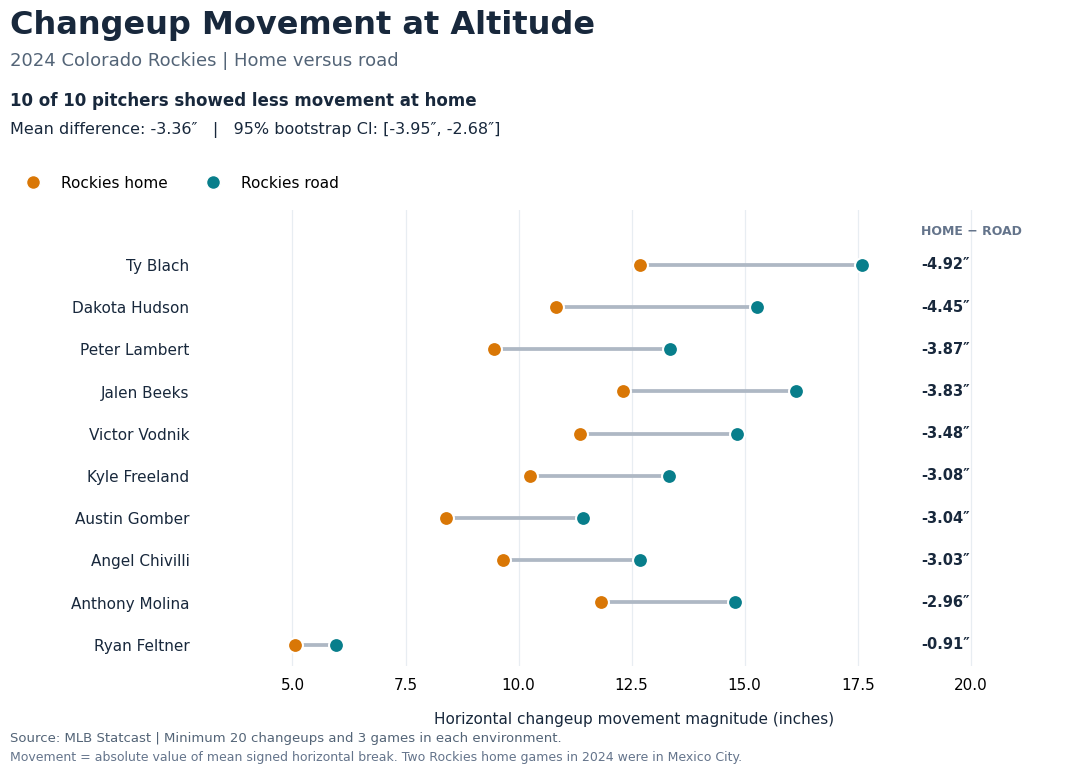

Figure 1 saved:
/content/drive/MyDrive/Coors Project/figures/figure_1_changeup_home_road.png
/content/drive/MyDrive/Coors Project/figures/figure_1_changeup_home_road.pdf


In [26]:
# ============================================================
# FIGURE 1 — 2024 ROCKIES CHANGEUP MOVEMENT
# Publication-ready connected-dot chart
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")
FIGURE_PATH = DATA_PATH / "figures"
FIGURE_PATH.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load audited research results
# ------------------------------------------------------------

df = pd.read_csv(
    DATA_PATH / "coors_2024_changeup_validation.csv"
)

stats = pd.read_csv(
    DATA_PATH / "coors_changeup_final_statistics.csv"
)

valid = df[
    df["sufficient_sample"]
    .astype(str).str.lower().eq("true")
].copy()

assert len(valid) == 10
assert valid["player_id"].nunique() == 10

valid = valid.sort_values("difference").reset_index(drop=True)

def format_name(name):
    if ", " in name:
        last, first = name.split(", ", 1)
        return f"{first} {last}"
    return name

valid["display_name"] = valid["player_name"].map(format_name)

mean_diff = float(stats["mean_difference"].iloc[0])
ci_lower = float(stats["ci_lower"].iloc[0])
ci_upper = float(stats["ci_upper"].iloc[0])

# ------------------------------------------------------------
# 2. Professional chart styling
# ------------------------------------------------------------

HOME = "#D97706"
ROAD = "#087E8B"
NAVY = "#18283C"
GREY = "#AEB8C4"
LIGHT = "#E8EDF2"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "savefig.facecolor": "white"
})

fig, ax = plt.subplots(figsize=(12, 8))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

y = np.arange(len(valid))

# ------------------------------------------------------------
# 3. Plot individual pitcher comparisons
# ------------------------------------------------------------

for i, row in valid.iterrows():

    home = row["home_movement"]
    road = row["road_movement"]

    # Connect the two environments
    ax.plot(
        [home, road],
        [i, i],
        color=GREY,
        linewidth=2.7,
        solid_capstyle="round",
        zorder=2
    )

    # Coors-designated home
    ax.scatter(
        home, i,
        s=115,
        color=HOME,
        edgecolor="white",
        linewidth=1.5,
        zorder=4
    )

    # Rockies road
    ax.scatter(
        road, i,
        s=115,
        color=ROAD,
        edgecolor="white",
        linewidth=1.5,
        zorder=4
    )

# ------------------------------------------------------------
# 4. Difference column
# ------------------------------------------------------------

max_movement = valid[
    ["home_movement", "road_movement"]
].max().max()

difference_x = max_movement + 1.3

for i, row in valid.iterrows():

    ax.text(
        difference_x,
        i,
        f'{row["difference"]:+.2f}″',
        ha="left",
        va="center",
        fontsize=10.5,
        weight="bold",
        color=NAVY
    )

ax.text(
    difference_x,
    -0.8,
    "HOME − ROAD",
    ha="left",
    va="center",
    fontsize=9,
    weight="bold",
    color="#64748B"
)

# ------------------------------------------------------------
# 5. Axes and labels
# ------------------------------------------------------------

ax.set_yticks(y)
ax.set_yticklabels(
    valid["display_name"],
    fontsize=11,
    color=NAVY
)

ax.set_ylim(len(valid) - 0.5, -1.3)

ax.set_xlim(3, max_movement + 4.5)

ax.set_xlabel(
    "Horizontal changeup movement magnitude (inches)",
    fontsize=11,
    color=NAVY,
    labelpad=13
)

ax.grid(
    axis="x",
    color=LIGHT,
    linewidth=0.9
)

ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, pad=9)

for spine in ax.spines.values():
    spine.set_visible(False)

# ------------------------------------------------------------
# 6. Titles and findings
# ------------------------------------------------------------

fig.text(
    0.07, 0.95,
    "Changeup Movement at Altitude",
    fontsize=23,
    fontweight="bold",
    color=NAVY
)

fig.text(
    0.07, 0.91,
    "2024 Colorado Rockies | Home versus road",
    fontsize=13,
    color="#536477"
)

fig.text(
    0.07, 0.86,
    f"10 of 10 pitchers showed less movement at home",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

fig.text(
    0.07, 0.825,
    f"Mean difference: {mean_diff:.2f}″   "
    f"|   95% bootstrap CI: "
    f"[{ci_lower:.2f}″, {ci_upper:.2f}″]",
    fontsize=11.5,
    color=NAVY
)

# ------------------------------------------------------------
# 7. Legend
# ------------------------------------------------------------

legend_items = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=HOME,
        markeredgecolor="white",
        markersize=10,
        label="Rockies home"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=ROAD,
        markeredgecolor="white",
        markersize=10,
        label="Rockies road"
    )
]

fig.legend(
    handles=legend_items,
    loc="upper left",
    bbox_to_anchor=(0.065, 0.79),
    frameon=False,
    ncol=2,
    fontsize=11
)

# ------------------------------------------------------------
# 8. Research footnotes
# ------------------------------------------------------------

fig.text(
    0.07, 0.065,
    "Source: MLB Statcast | Minimum 20 changeups and "
    "3 games in each environment.",
    fontsize=9.5,
    color="#536477"
)

fig.text(
    0.07, 0.041,
    "Movement = absolute value of mean signed horizontal "
    "break. Two Rockies home games in 2024 were in Mexico City.",
    fontsize=9,
    color="#64748B"
)

fig.subplots_adjust(
    left=0.23,
    right=0.95,
    top=0.73,
    bottom=0.16
)

# ------------------------------------------------------------
# 9. Save high-resolution publication files
# ------------------------------------------------------------

png_path = FIGURE_PATH / "figure_1_changeup_home_road.png"
pdf_path = FIGURE_PATH / "figure_1_changeup_home_road.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure 1 saved:")
print(png_path)
print(pdf_path)

Figure 2 — Movement differences across seven pitch types

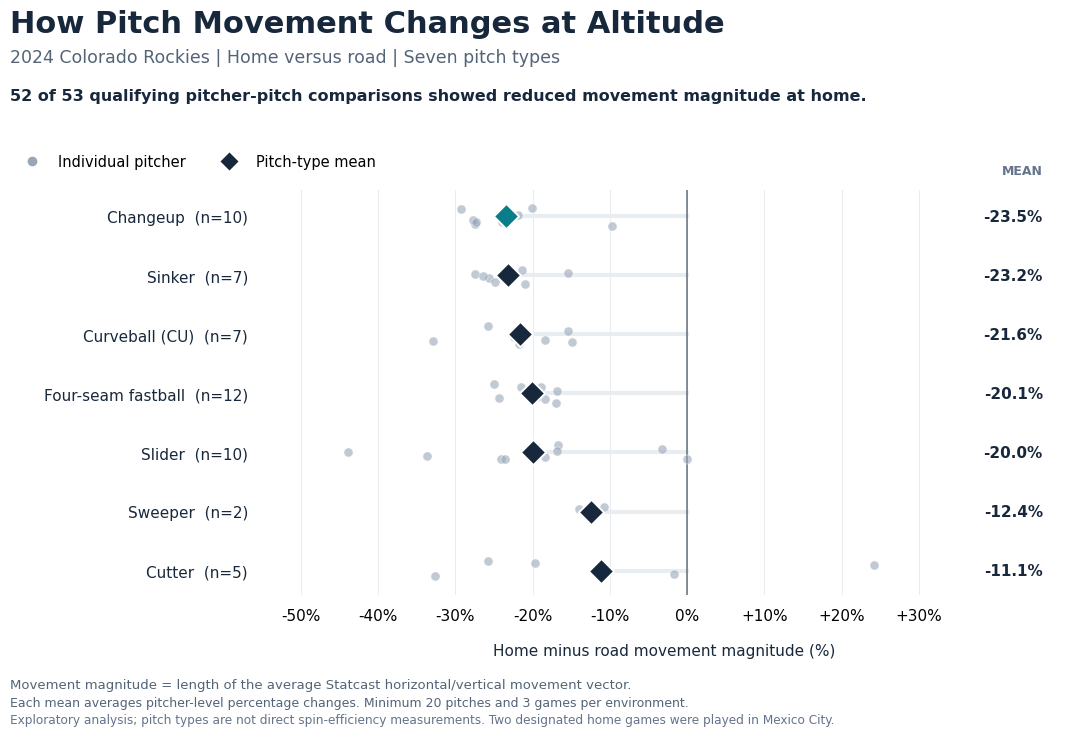

Figure 2 saved:
/content/drive/MyDrive/Coors Project/figures/figure_2_pitch_type_comparison.png
/content/drive/MyDrive/Coors Project/figures/figure_2_pitch_type_comparison.pdf

PITCH-TYPE SUMMARY


,pitch_type,pitchers,mean_pct,lower_at_home
0,changeup,10,-23.49,10
1,sinker,7,-23.17,7
2,curveball,7,-21.64,7
3,four_seam,12,-20.05,12
4,slider,10,-20.01,10
5,sweeper,2,-12.38,2
6,cutter,5,-11.14,4


In [27]:
# ============================================================
# FIGURE 2 — MOVEMENT DIFFERENCES BY PITCH TYPE
# Publication-quality exploratory comparison
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")
FIGURE_PATH = DATA_PATH / "figures"
FIGURE_PATH.mkdir(parents=True, exist_ok=True)

# 1. Load audited results
df = pd.read_csv(
    DATA_PATH / "coors_2024_pitch_type_movement_detail.csv"
)

valid = df[
    df["sufficient_sample"]
    .astype(str).str.lower().eq("true")
].copy()

assert len(valid) == 53

summary = (
    valid.groupby("pitch_type")
    .agg(
        pitchers=("player_id", "nunique"),
        mean_pct=("pct_difference", "mean"),
        lower_at_home=(
            "pct_difference",
            lambda x: int((x < 0).sum())
        )
    )
    .reset_index()
    .sort_values("mean_pct")
    .reset_index(drop=True)
)

labels = {
    "four_seam": "Four-seam fastball",
    "sinker": "Sinker",
    "changeup": "Changeup",
    "curveball": "Curveball (CU)",
    "slider": "Slider",
    "cutter": "Cutter",
    "sweeper": "Sweeper"
}

# 2. Styling
NAVY = "#18283C"
TEAL = "#087E8B"
GREY = "#98A7B8"
LIGHT = "#E8EDF2"

fig, ax = plt.subplots(figsize=(12, 7.5))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

rng = np.random.default_rng(42)

# 3. Plot each pitch type
for i, row in summary.iterrows():

    pitch = row["pitch_type"]
    values = valid.loc[
        valid["pitch_type"] == pitch,
        "pct_difference"
    ].to_numpy()

    # Individual observations, slightly offset vertically
    jitter = rng.uniform(-0.17, 0.17, len(values))

    ax.scatter(
        values,
        i + jitter,
        s=43,
        color=GREY,
        alpha=0.60,
        edgecolor="white",
        linewidth=0.5,
        zorder=3
    )

    mean = row["mean_pct"]

    # Connect mean to zero
    ax.plot(
        [mean, 0],
        [i, i],
        color=LIGHT,
        linewidth=3,
        zorder=1
    )

    # Mean marker
    ax.scatter(
        mean, i,
        s=165,
        marker="D",
        color=TEAL if pitch == "changeup" else NAVY,
        edgecolor="white",
        linewidth=1.4,
        zorder=5
    )

    # Dedicated mean-value column
    ax.text(
        46, i,
        f"{mean:+.1f}%",
        ha="right",
        va="center",
        fontsize=11,
        fontweight="bold",
        color=NAVY
    )

# 4. Axes
y = np.arange(len(summary))

ax.set_yticks(y)
ax.set_yticklabels(
    [
        f"{labels[row.pitch_type]}  (n={row.pitchers})"
        for row in summary.itertuples()
    ],
    fontsize=11,
    color=NAVY
)

ax.invert_yaxis()

ax.set_xlim(-55, 49)

ax.axvline(
    0,
    color=NAVY,
    linewidth=1.2,
    alpha=0.6
)

ax.set_xticks([-50, -40, -30, -20, -10, 0, 10, 20, 30])
ax.set_xticklabels(
    ["-50%", "-40%", "-30%", "-20%", "-10%",
     "0%", "+10%", "+20%", "+30%"]
)

ax.grid(axis="x", color=LIGHT, linewidth=0.8)
ax.set_axisbelow(True)

ax.tick_params(axis="both", length=0, pad=10)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xlabel(
    "Home minus road movement magnitude (%)",
    fontsize=11,
    color=NAVY,
    labelpad=14
)

ax.text(
    46, -0.72,
    "MEAN",
    ha="right",
    fontsize=9,
    fontweight="bold",
    color="#64748B"
)

# 5. Title and subtitle
fig.text(
    0.07, 0.95,
    "How Pitch Movement Changes at Altitude",
    fontsize=22,
    fontweight="bold",
    color=NAVY
)

fig.text(
    0.07, 0.91,
    "2024 Colorado Rockies | Home versus road | Seven pitch types",
    fontsize=12.5,
    color="#536477"
)

fig.text(
    0.07, 0.86,
    "52 of 53 qualifying pitcher-pitch comparisons "
    "showed reduced movement magnitude at home.",
    fontsize=11.5,
    fontweight="bold",
    color=NAVY
)

# 6. Legend
legend_items = [
    Line2D(
        [0], [0], marker="o", linestyle="None",
        markerfacecolor=GREY, markeredgecolor="white",
        markersize=8, label="Individual pitcher"
    ),
    Line2D(
        [0], [0], marker="D", linestyle="None",
        markerfacecolor=NAVY, markeredgecolor="white",
        markersize=10, label="Pitch-type mean"
    )
]

fig.legend(
    handles=legend_items,
    loc="upper left",
    bbox_to_anchor=(0.065, 0.805),
    frameon=False,
    ncol=2,
    fontsize=10.5
)

# 7. Notes
fig.text(
    0.07, 0.075,
    "Movement magnitude = length of the average Statcast "
    "horizontal/vertical movement vector.",
    fontsize=9.5,
    color="#536477"
)

fig.text(
    0.07, 0.052,
    "Each mean averages pitcher-level percentage changes. "
    "Minimum 20 pitches and 3 games per environment.",
    fontsize=9,
    color="#536477"
)

fig.text(
    0.07, 0.029,
    "Exploratory analysis; pitch types are not direct spin-efficiency "
    "measurements. Two designated home games were played in Mexico City.",
    fontsize=8.7,
    color="#64748B"
)

fig.subplots_adjust(
    left=0.28,
    right=0.95,
    top=0.74,
    bottom=0.20
)

# 8. Save
png_path = FIGURE_PATH / "figure_2_pitch_type_comparison.png"
pdf_path = FIGURE_PATH / "figure_2_pitch_type_comparison.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure 2 saved:")
print(png_path)
print(pdf_path)

print("\nPITCH-TYPE SUMMARY")
display(summary.round(2))

Figure 3 — Is the Rockies changeup difference ordinary MLB variation?

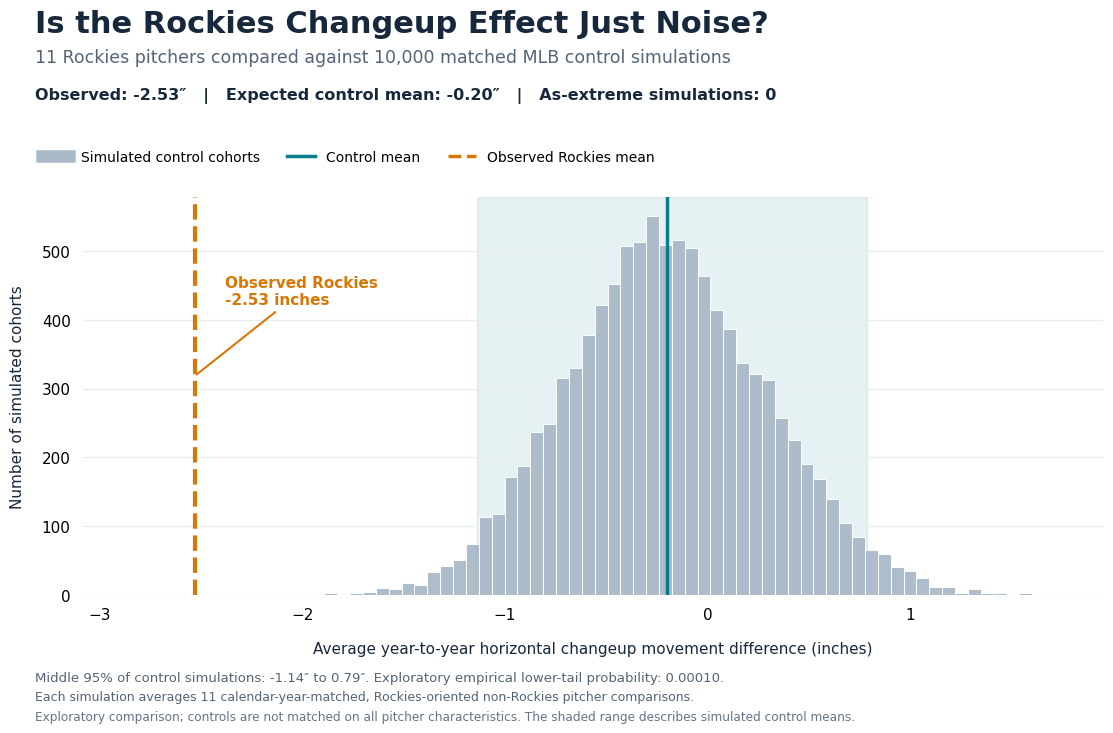


FIGURE 3 SUMMARY
Rockies pitchers: 11
Simulated cohorts: 10000
Observed Rockies mean: -2.532
Control mean: -0.201
Control central 95%: [-1.136  0.791]
Simulations as extreme as observed: 0
Exploratory empirical probability: 0.0001

Figure 3 saved:
/content/drive/MyDrive/Coors Project/figures/figure_3_changeup_control_simulation.png
/content/drive/MyDrive/Coors Project/figures/figure_3_changeup_control_simulation.pdf


In [28]:
# ============================================================
# FIGURE 3 — ROCKIES VS MLB YEAR-TO-YEAR VARIATION
# Publication-ready simulation histogram
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Coors Project")
FIGURE_PATH = DATA_PATH / "figures"
FIGURE_PATH.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load audited research results
# ------------------------------------------------------------

simulations = pd.read_csv(
    DATA_PATH / "coors_changeup_control_simulations.csv"
)

rockies = pd.read_csv(
    DATA_PATH / "coors_changeup_robustness.csv"
)

control_values = simulations["simulated_mean"].dropna().to_numpy()
rockies_values = rockies["movement_change"].dropna().to_numpy()

assert len(control_values) == 10000
assert len(rockies_values) == 11

observed_mean = rockies_values.mean()
control_mean = control_values.mean()

ci_lower, ci_upper = np.percentile(
    control_values, [2.5, 97.5]
)

more_extreme = int(
    (control_values <= observed_mean).sum()
)

empirical_p = (
    more_extreme + 1
) / (
    len(control_values) + 1
)

# ------------------------------------------------------------
# 2. Professional styling
# ------------------------------------------------------------

NAVY = "#18283C"
TEAL = "#087E8B"
ORANGE = "#D97706"
LIGHT = "#E8EDF2"
HIST = "#AABAC9"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "savefig.facecolor": "white"
})

fig, ax = plt.subplots(figsize=(12, 7.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# ------------------------------------------------------------
# 3. Plot simulated control distribution
# ------------------------------------------------------------

ax.hist(
    control_values,
    bins=55,
    color=HIST,
    edgecolor="white",
    linewidth=0.7,
    alpha=0.95,
    zorder=2
)

# Central 95% of control simulations
ax.axvspan(
    ci_lower,
    ci_upper,
    color=TEAL,
    alpha=0.10,
    zorder=0
)

# Control mean
ax.axvline(
    control_mean,
    color=TEAL,
    linewidth=2.5,
    zorder=4
)

# Actual Rockies result
ax.axvline(
    observed_mean,
    color=ORANGE,
    linewidth=3,
    linestyle="--",
    zorder=5
)

# ------------------------------------------------------------
# 4. Axes
# ------------------------------------------------------------

x_min = min(
    observed_mean - 0.55,
    control_values.min() - 0.3
)

x_max = control_values.max() + 0.35

ax.set_xlim(x_min, x_max)

ax.set_xlabel(
    "Average year-to-year horizontal changeup "
    "movement difference (inches)",
    fontsize=11,
    color=NAVY,
    labelpad=14
)

ax.set_ylabel(
    "Number of simulated cohorts",
    fontsize=11,
    color=NAVY,
    labelpad=12
)

ax.grid(
    axis="y",
    color=LIGHT,
    linewidth=0.9
)

ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, pad=9)

for spine in ax.spines.values():
    spine.set_visible(False)

# Label the observed result near its vertical line
y_max = ax.get_ylim()[1]

ax.annotate(
    f"Observed Rockies\n{observed_mean:.2f} inches",
    xy=(observed_mean, y_max * 0.55),
    xytext=(observed_mean + 0.15, y_max * 0.73),
    fontsize=11,
    fontweight="bold",
    color=ORANGE,
    ha="left",
    arrowprops={
        "arrowstyle": "-",
        "color": ORANGE,
        "linewidth": 1.5
    }
)

# ------------------------------------------------------------
# 5. Titles and summary
# ------------------------------------------------------------

fig.text(
    0.07, 0.95,
    "Is the Rockies Changeup Effect Just Noise?",
    fontsize=22,
    fontweight="bold",
    color=NAVY
)

fig.text(
    0.07, 0.91,
    "11 Rockies pitchers compared against "
    "10,000 matched MLB control simulations",
    fontsize=12.5,
    color="#536477"
)

fig.text(
    0.07, 0.86,
    f"Observed: {observed_mean:.2f}″   "
    f"|   Expected control mean: {control_mean:.2f}″   "
    f"|   As-extreme simulations: {more_extreme:,}",
    fontsize=11.5,
    fontweight="bold",
    color=NAVY
)

# ------------------------------------------------------------
# 6. Legend
# ------------------------------------------------------------

legend_items = [
    Line2D(
        [0], [0],
        color=HIST,
        linewidth=9,
        label="Simulated control cohorts"
    ),
    Line2D(
        [0], [0],
        color=TEAL,
        linewidth=2.5,
        label="Control mean"
    ),
    Line2D(
        [0], [0],
        color=ORANGE,
        linewidth=2.5,
        linestyle="--",
        label="Observed Rockies mean"
    )
]

fig.legend(
    handles=legend_items,
    loc="upper left",
    bbox_to_anchor=(0.065, 0.81),
    frameon=False,
    ncol=3,
    fontsize=10
)

# ------------------------------------------------------------
# 7. Research footnotes
# ------------------------------------------------------------

fig.text(
    0.07, 0.085,
    f"Middle 95% of control simulations: "
    f"{ci_lower:.2f}″ to {ci_upper:.2f}″. "
    f"Exploratory empirical lower-tail probability: "
    f"{empirical_p:.5f}.",
    fontsize=9.5,
    color="#536477"
)

fig.text(
    0.07, 0.059,
    "Each simulation averages 11 calendar-year-matched, "
    "Rockies-oriented non-Rockies pitcher comparisons.",
    fontsize=9,
    color="#536477"
)

fig.text(
    0.07, 0.033,
    "Exploratory comparison; controls are not matched "
    "on all pitcher characteristics. "
    "The shaded range describes simulated control means.",
    fontsize=8.7,
    color="#64748B"
)

fig.subplots_adjust(
    left=0.11,
    right=0.96,
    top=0.73,
    bottom=0.20
)

# ------------------------------------------------------------
# 8. Save publication files
# ------------------------------------------------------------

png_path = FIGURE_PATH / "figure_3_changeup_control_simulation.png"
pdf_path = FIGURE_PATH / "figure_3_changeup_control_simulation.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nFIGURE 3 SUMMARY")
print("Rockies pitchers:", len(rockies_values))
print("Simulated cohorts:", len(control_values))
print("Observed Rockies mean:", round(observed_mean, 3))
print("Control mean:", round(control_mean, 3))
print(
    "Control central 95%:",
    np.round([ci_lower, ci_upper], 3)
)
print("Simulations as extreme as observed:", more_extreme)
print("Exploratory empirical probability:", round(empirical_p, 6))

print("\nFigure 3 saved:")
print(png_path)
print(pdf_path)